# M7 — esteira instrumentada: plano de construção e testes (bancada + gêmeo Wokwi)

**VOCAID DEEP · Masterclass 12/11/2026.** Este notebook junta, num só lugar, o que a turma precisa para reproduzir o circuito M7: o plano, as peças e os pinos, as regras de segurança, as fases de teste com o status real, o código do gêmeo Wokwi e uma análise executável do z-score com a mesma regra do firmware.

**Status real em 09/11/2026:** etapas **1 e 2 PASSARAM** na placa real. As etapas 0, 3, 4, 5, 5b, 6 e 7 estão **pendentes**. Onde a bancada ainda não mediu, o notebook diz **lacuna** e não inventa número.

Fontes no repositório `masterclass-12-11`: `BANCADA-ENSAIO.md`, `arduino-mega-esteira-ky/`, `esp8266-esteira-app/`, `wokwi-mega-esteira-ky/`, `evidencias/2026-11-0[89]-*` e `sinais/`. O notebook foi gerado por `colab/gerar_notebook.py`, que lê esses arquivos (nada foi redigitado).

**Como usar no Colab:** *Ambiente de execução → Executar tudo*. Não precisa de hardware nem de internet além do próprio Colab: os arquivos do gêmeo e as seriais de exemplo são gravados pelas células.

## 1. Visão geral

Três sensores baratos (óptico, som e vibração) vigiam um motor DC com volante. O Arduino Mega transforma cada janela de 1 s num **escore de saúde calibrado** e corta o motor por um relé quando o escore sai do normal.

- **O E físico em série.** O motor só gira se o **relé A** (NodeMCU: "o app aprovou", `esteira: ligada` no `meta` do artigo) **E** o **relé B** (Mega: "a IA não disparou") estiverem fechados. Os dois contatos ficam em série no caminho de potência: qualquer um que abra corta o motor, sem software no meio.
- **z-score calibrado.** 3 janelas de aquecimento são descartadas e 30 janelas calibram a média e o desvio de cada canal (rpm, som_rms, vib). Cada desvio tem um piso: rpm 60, som 3 e vib 2. Depois, `z = (x − média) / desvio` por canal e `score = max |z|`.
- **ALERTA travado.** Dispara com `score > 3,0` (estrito) em **2 janelas seguidas**: o relé B abre, o LED vermelho acende e o buzzer toca. Não há rearme automático; só o reset da placa rearma (e recalibra, uns 33 s).
- **SUSPEITA.** Se o rpm médio da calibração ficar abaixo de 60 (motor parado), o Mega corta o motor e não arma o ALERTA até o reset.

Não é rede neural: é estatística calibrada. O upgrade seria um MLP int8, como no módulo de impacto.

Diagrama de ligação (`evidencias/2026-11-09-diagrama-ligacao.png`):

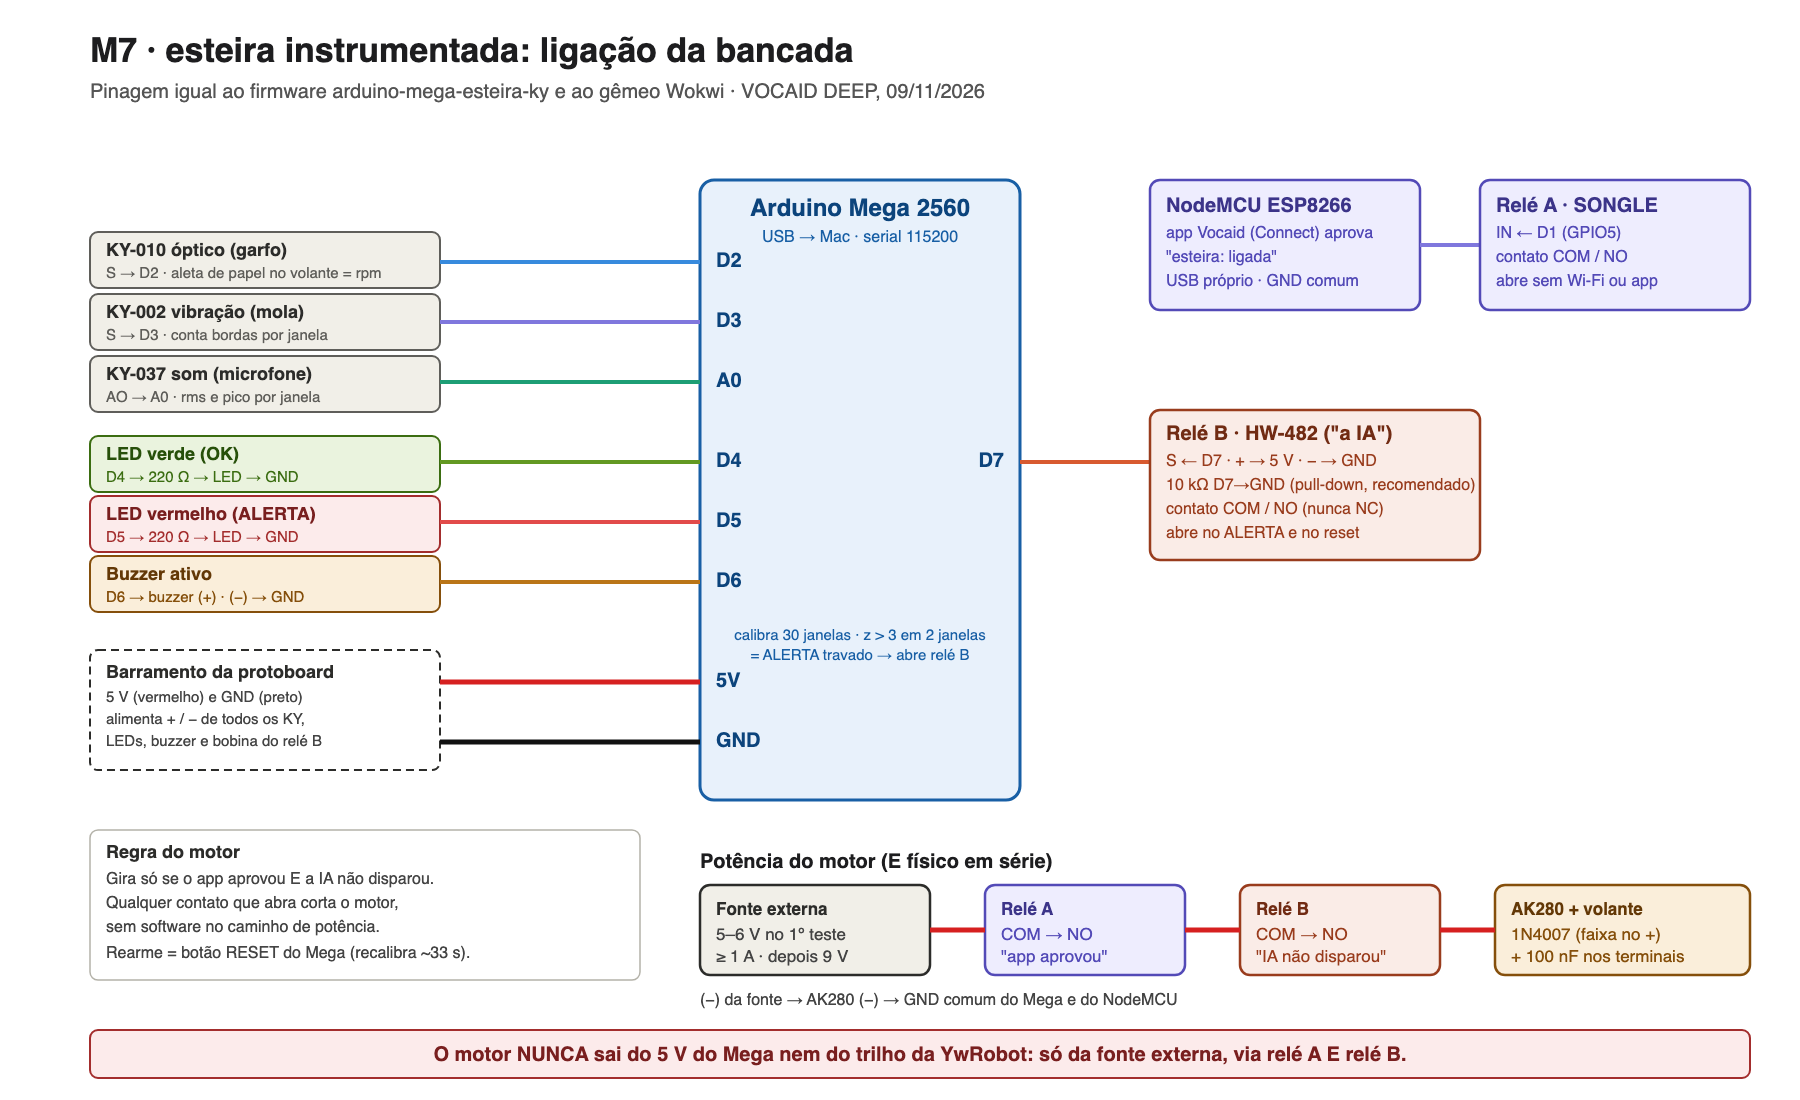

## 2. Peças, pinos e segurança

### Peças e pinos

| Peça | Liga em | Observação | Situação em 09/11 |
|---|---|---|---|
| Arduino Mega 2560 | USB do computador | firmware `arduino-mega-esteira-ky.ino` (= `sketch.ino` do gêmeo) | **testado** (etapa 1) |
| KY-010 (óptico), `S` | D2 (INT4) | 1 aleta de papel = 1 pulso por volta; guardas de 200 µs e 2 ms | **falta** |
| KY-037 (som), `AO` | A0 | amostrado a ~1 kHz; trimpot no meio da faixa | lacuna (etapa 3) |
| KY-002 (vibração), `S` | D3 (INT5) | conta todas as bordas (1 evento = 2 bordas) | lacuna (etapa 3) |
| Relé B: HW-482 no lugar do KY-019, `S` / `+` / `-` | D7 / 5 V / GND | ativo em ALTO (`RELE_ATIVO_BAIXO = false`); contato **COM–NO** | **testado** (etapa 2) |
| LED verde (OK) | D4 + 220 Ω | pisca na calibração, fixo no NORMAL | lacuna (etapa 3) |
| LED vermelho (ALERTA) | D5 + 220 Ω | | lacuna |
| Buzzer ativo | D6 | | lacuna |
| NodeMCU ESP8266 + módulo do relé A | IN no D1 (GPIO5); VCC no 3V3 ou VIN; GND comum | `RELE_ATIVO_BAIXO = true` por padrão; contato **COM–NO** | lacuna (etapa 4) |
| NPN 2N2222 ou BC547 + 1 kΩ (base) + 10 kΩ (base–emissor) | entre D1 e o IN do relé A | só se o relé A não clicar com 3,3 V; aí `RELE_ATIVO_BAIXO = false` | se precisar |
| Motor Akiyama AK280 + volante de latão | adaptador externo, via relé A e relé B | parte em 5–6 V, roda em 9 V, máx. 12 V | lacuna (etapa 5) |
| Adaptador externo ≥ 1 A | potência do motor | ajustado no **menor** valor no 1º teste | **falta** |
| Diodo 1N4007 | terminais do motor, faixa no + | absorve o pico de abertura do relé | **falta** |
| Capacitor cerâmico 100 nF | terminais do motor | corta o ruído das escovas | **falta** |
| Aleta de papel 5–15 mm | aro do volante | nunca mais da metade do aro | lacuna |
| Multímetro, óculos, grampo, copo ou caixa transparente | — | etapa 0 | lacuna |
| (5b, opcional) KY-008 laser + KY-018 fotorresistor | 5 V / GND; `S` do KY-018 no D2 | barreira de laser no lugar do KY-010 | opcional |

"Falta" = peça que a sessão da bancada registrou como ainda não disponível em 09/11. "Lacuna" = ainda não conferido em bancada.

### Regras de segurança (não negociáveis)

1. **O motor só sai do adaptador externo.** Nunca no 5 V do Mega, nunca no trilho AMS1117 da YwRobot: a corrente de partida derruba o trilho, reinicia o Mega e pode queimar o regulador.
2. **GND comum:** Mega, NodeMCU, adaptador (−) e os módulos no mesmo GND.
3. **COM/NO, nunca NC**, nos dois relés. NC fecharia o motor justamente com o relé desligado.
4. **Relé A em 3,3 V:** o GPIO do NodeMCU pode não acionar um módulo de 5 V. Se não clicar nas duas polaridades, use o NPN (tabela acima) e grave com `RELE_ATIVO_BAIXO = false`.
5. **Motor desconectado** nas etapas 1–4. Ele só entra na etapa 5, depois das duas checagens de relé.
6. **Diodo e capacitor** nos terminais do motor. Se o Mega reiniciar quando o motor parte, o problema é a alimentação ou o capacitor, não o sketch.
7. **Mecânica:** óculos, volante preso por grampo e coberto, sem mangas nem cabelo soltos, dedos longe do eixo, primeiro teste na menor tensão.
8. **Laser (5b):** nunca nos olhos nem na lente da câmera.

```
adaptador externo (+) → COM–NO do relé A (NodeMCU) → COM–NO do relé B (Mega, D7) → AK280 (+)
adaptador externo (−) → AK280 (−) → GND do Mega e do NodeMCU (GND comum)
```

## 3. Fases de teste, etapa por etapa

Roteiro de `BANCADA-ENSAIO.md`. **Não pule etapas.** Os comandos rodam na raiz do repositório; `<MEGA>` e `<NODE>` são as portas que aparecem em `arduino-cli board list`. Só um programa por porta: feche o Serial Monitor da IDE antes do `upload` e antes do registrador.

| Etapa | O quê | Status em 09/11/2026 |
|---|---|---|
| 0 | preparo, sem energia | **pendente** (faltam a fonte ≥ 1 A, o 1N4007 e o 100 nF) |
| 1 | Mega sozinho no USB | **PASSOU** (08:55; 17/17, `# SUSPEITA` 33 s depois do cabeçalho) |
| 2 | relé B no D7, motor desconectado | **PASSOU** (11:20; HW-482 ativo em ALTO; COM–NO abre em 33,1 s) |
| 3 | sensores no Mega, motor desconectado | **pendente** (falta o KY-010) |
| 4 | NodeMCU e relé A, motor desconectado | **pendente** |
| 5 | motor em baixa tensão, A e B em série | **pendente** |
| 5b | (opcional) rpm por barreira de laser | **pendente** |
| 6 | validade dos gestos `a m p s r` | **pendente** |
| 7 | shakedown e gravação do ensaio | **pendente** |

### Etapa 0 — preparo (sem energia) · **pendente**

- Óculos, volante preso por grampo e coberto, adaptador externo ≥ 1 A no **menor** valor (5–6 V).
- Diodo 1N4007 nos terminais do AK280 (faixa no +) e capacitor cerâmico de 100 nF nos terminais.
- Aleta de papel de 5–15 mm no aro, passando pela fenda do KY-010 sem raspar.
- Multímetro em continuidade.

**Lacuna:** em 09/11 ainda faltavam o KY-010, a fonte externa ≥ 1 A, o 1N4007 e o capacitor de 100 nF.

### Etapa 1 — Mega sozinho no USB (nada nos pinos) · **PASSOU em 09/11**

```bash
arduino-cli upload --fqbn arduino:avr:mega -p <MEGA> arduino-mega-esteira-ky
arduino-cli monitor -p <MEGA> -c baudrate=115200
```

**Passa se** a serial mostrar `AUTO-TESTE: 17/17 -> PASS`, a linha de método, o cabeçalho CSV e, uns 33 s depois, `# SUSPEITA` (sem motor, isso é o esperado). **Pare** se o autoteste falhar ou a serial sair com lixo (baud ou porta errados).

Serial real, em trechos (`evidencias/2026-11-09-bancada-etapa-1.txt`; coluna 1 = epoch no Mac; a serial completa vai para a seção 5):

```
Etapa 1 (Mega sozinho no USB, nada nos pinos) - bancada fisica, 2026-11-09 08:55 -0300
Placa: Arduino Mega 2560 (USB VID 2341 PID 0042, original), porta /dev/cu.usbmodemXXXX
Firmware: arduino-mega-esteira-ky.ino sha256 fded3890...cd7247 (identico ao wokwi-mega-esteira-ky/sketch.ino); 11054 B flash, 653 B RAM
Resultado: PASSOU - AUTO-TESTE 17/17 PASS, linha de metodo, cabecalho CSV, # SUSPEITA 33 s depois do cabecalho (esperado sem motor).
1794225275.9 # metodo: estatistica calibrada (z-score); upgrade: MLP int8 como no modulo de impacto
1794225276.0 AUTO-TESTE: 17/17 -> PASS
1794225276.0 janela,rpm,som_rms,som_pico,vib,score,estado
1794225277.0 1,0,25.7,58,0,0.0,AQUECENDO
1794225278.0 2,0,19.2,35,0,0.0,AQUECENDO
1794225279.0 3,0,19.0,31,0,0.0,AQUECENDO
1794225280.0 4,0,19.1,30,0,0.0,CALIBRANDO
1794225308.0 32,0,18.9,30,0,0.0,CALIBRANDO
1794225309.0 # calibrado: c0 media=0.0 desvio=60.00 c1 media=18.8 desvio=3.00 c2 media=0.0 desvio=2.00
1794225309.0 # SUSPEITA: motor cortado -- de reset com o motor girando
1794225309.0 33,0,19.0,30,0,0.0,CALIBRANDO
1794225310.0 34,0,19.0,30,0,0.0,SUSPEITA
```

O `som_rms` de ~19 é o A0 flutuando, sem nada ligado; **não é medida de sensor**. A célula da seção 5 recalcula o tempo até a `# SUSPEITA` a partir desta serial.

### Etapa 2 — relé B no Mega, motor DESCONECTADO · **PASSOU em 09/11**

Ligação: `S` no D7, `+` no 5 V, `-` no GND. Multímetro em continuidade entre **COM e NO**. Nada no contato.

| Momento | COM–NO esperado |
|---|---|
| segurando RESET, boot e AUTO-TESTE | **ABERTO** |
| depois do cabeçalho CSV | **FECHADO** (clique) |
| depois do `# SUSPEITA` (~33 s) | **ABERTO** de novo |

**Pare** se algum estado sair invertido: troque `RELE_ATIVO_BAIXO`, regrave e repita a tabela inteira. Use NO, nunca NC.

Resultado real (`evidencias/2026-11-09-bancada-etapa-2.txt`):

```
Etapa 2 (rele B HW-482 no Mega, motor DESCONECTADO) - bancada fisica, 2026-11-09 11:20 -0300
Ligacao final: S -> D7, + -> 5V (trilho da protoboard alimentado pelo 5V do Mega), - -> GND. Multimetro em continuidade entre COM (parafuso do meio) e NO.
Firmware: o mesmo da etapa 1 (sha256 fded3890...cd7247), RELE_ATIVO_BAIXO = false (sem alteracao).
- 1a tentativa: sem bipe. Causa: o + do rele estava no GND (bobina sem alimentacao). O LED do modulo acendia mesmo assim, entao LED aceso nao prova rele fechado.
- Teste manual com o fio do S: encostado no trilho 5V o rele clica; no GND nao clica. Modulo ATIVO EM ALTO, como o firmware assume.
- Terminal NC identificado (bipa em repouso); o NO e o parafuso da outra ponta.
Resultado: PASSOU (operador confirmou a sequencia completa):
| Momento | COM-NO esperado | Observado |
| boot / AUTO-TESTE | ABERTO | silencio |
| depois do cabecalho CSV (0,0 s) | FECHADO | clique + bipe continuo |
| # SUSPEITA (33,1 s) | ABERTO | clique, silencio |
1794233992.0 # calibrado: c0 media=0.0 desvio=60.00 c1 media=18.3 desvio=3.00 c2 media=0.0 desvio=2.00
1794233992.0 # SUSPEITA: motor cortado -- de reset com o motor girando
```

Lição da bancada: o LED do módulo acendia com o `+` do relé no GND, ou seja, **LED aceso não prova relé fechado**. Confira sempre com o multímetro.

### Etapa 3 — sensores no Mega, motor DESCONECTADO · **pendente**

Ligação: KY-010 `S` no D2, KY-037 `AO` no A0, KY-002 `S` no D3; `-` no GND e `+` (ou o pino do meio) no 5 V. LEDs no D4 (verde) e no D5 (vermelho) com 220 Ω, buzzer no D6.

```bash
sinais/.venv/bin/python -I sinais/registrador.py --serial <MEGA> --saida sinais/sessoes/teste-sensores
```

Durante AQUECENDO e CALIBRANDO:

- **óptico:** papel pela fenda do KY-010 várias vezes por segundo → `rpm` sobe de 0 (anote a polaridade do LED do módulo);
- **som:** palmas perto do KY-037 → `som_rms` e `som_pico` sobem (se ficar em 0 ou ~1023, ajuste o trimpot);
- **vibração:** tapinhas na mola do KY-002 → `vib` sobe.

**Serial esperada:** o mesmo cabeçalho da etapa 1; os valores dependem dos gestos. **Lacuna:** nenhum canal foi medido ainda. **Pare** se um canal ficar parado: fio ou pino errado.

### Etapa 4 — NodeMCU e relé A, motor DESCONECTADO · **pendente**

**4a. Polaridade, sem rede.** `cp esp8266-esteira-app/segredos.exemplo.h esp8266-esteira-app/segredos.h` com um SSID **errado**, e grave:

```bash
arduino-cli upload --fqbn esp8266:esp8266:nodemcuv2 -p <NODE> esp8266-esteira-app
```

| Momento | COM–NO do relé A |
|---|---|
| `# rele A aberto: wi-fi fora` | **ABERTO** |
| segurando RESET | **ABERTO** |
| partida, antes da 1ª consulta | **ABERTO** |

**4b. Positivo, com rede.** Chave **dedicada** com escopo `research:read` somente; você mesmo preenche Wi-Fi (2,4 GHz), chave e workspace em `segredos.h` (no `.gitignore`; nunca cole a chave em chat). Serial esperada: `AUTO-TESTE: 43/43 -> PASS`. Commit `esteira: ligada` → em até 10 s `# rele A fechado` e continuidade; `esteira: desligada` → ABERTO.

**Pare** se houver continuidade em 4a (inverta `RELE_ATIVO_BAIXO`; se não clicar em nenhuma polaridade, use o NPN). `ntp falhou` → hotspot do celular; `http 401/403` → chave ou escopo; `http 429` → cota (cada boot gasta 120 consultas nos primeiros 20 min; 4 boots num dia estouram 1000/dia). **Lacuna:** o relé A não rodou no hardware.

### Etapa 5 — motor em baixa tensão, A e B em série · **pendente**

```
adaptador (+) → COM–NO do relé A → COM–NO do relé B → AK280 (+)
adaptador (−) → AK280 (−) → GND do Mega e do NodeMCU (GND comum)
```

1. Commit `esteira: ligada` e espere `# rele A fechado` (segundo terminal: `arduino-cli monitor -p <NODE> -c baudrate=115200`).
2. Reset no Mega: o motor parte a 5–6 V. Espere `# calibrado:`. Nada tocando o volante.
3. Linhas `NORMAL` com `score` < 2; `rpm` estável e bem acima de 60, `som_rms` acima do silêncio, `vib` acima de 0.
4. Suba para 9 V só depois disso.

**Serial esperada (do gêmeo, é modelo e não medida):** `# calibrado: c0 media≈2000 … c1 media≈55 … c2 media≈5–6`, depois `NORMAL`. **Lacuna:** rpm, som e vib reais do AK280 não foram medidos; os alvos do chip do gêmeo são estimativas. **Pare** se o Mega reiniciar quando o motor parte (alimentação ou falta do capacitor) ou se aparecer `# SUSPEITA` com o motor girando.

### Etapa 5b (opcional) — rpm por barreira de laser · **pendente**

Firmware e gêmeo não mudam: o Mega só conta as transições para LOW no D2. KY-008 (`S` no 5 V, `-` no GND, sempre aceso) e KY-018 (`+` 5 V, `-` GND, `S` no **D2**, no lugar do `S` do KY-010), meia-lua de papel no aro e canudo sobre o fotorresistor. Faça **depois** da etapa 5.

- Sem motor: papel no feixe → `rpm` sobe de 0. O `S` do KY-018 tem de cruzar o meio da faixa (> 3 V ↔ < 1,5 V no multímetro).
- Com motor, mesma tensão: 30 s de `rpm` com o laser e 30 s com o KY-010.
- **Passa** se a média do laser ficar a até 5 % da do KY-010, sem janelas em 0. **Não passou:** volte ao KY-010; o laser vira só efeito visual.

**Lacuna:** não testado. O fotorresistor responde em ~10–50 ms e meio período a ~2000 rpm dá ~15 ms: pode não acompanhar.

### Etapa 6 — validade dos gestos (antes de gravar) · **pendente**

Cada gesto, uma vez, num reset novo, olhando a tela do registrador.

| Tecla | Gesto | Tem de acontecer | Se não acontecer |
|---|---|---|---|
| `a` | cotonete ou borracha num cabo no aro | `rpm` cai, som e vibração mudam → `ALERTA` em 2 janelas | toque mais firme; depois suba a tensão um degrau |
| `m` | fita sobre o microfone do KY-037 | só `som_*` cai | — |
| `p` | aleta solta ou dobrada | só `rpm` muda | se `rpm` e `vib` reais mudarem juntos, descarte o `p` |
| `s` | commit `esteira: desligada` | motor para; o Mega trava em `ALERTA` | — |
| `r` | barulho na sala, sem tocar a bancada | só som; é o falso alarme honesto | — |

**Referência do gêmeo (co-simulação de host, semente 1, falha na janela 40; modelo, não medida):** atrito → ALERTA na 41 (score 6,7); microfone → 41 (15,8); aleta → 41 (16,3); chave aberta → 41 (28,3); ruído da sala 100 → 41 (9,4). **Lacuna:** nenhum gesto foi feito na bancada.

### Etapa 7 — shakedown (09–10/11) e gravação do ensaio (11/11) · **pendente**

Abra o registrador primeiro → reset no Mega → `# calibrado` → ≥ 20 s em normal → tecla **antes** do gesto → gesto → `x` depois do disparo. Depois de um `s`: `esteira: ligada` e `# rele A fechado` **antes** do reset.

```bash
sinais/.venv/bin/python -I sinais/registrador.py --serial <MEGA> --saida sinais/sessoes/shakedown --firmware arduino-mega-esteira-ky/arduino-mega-esteira-ky.ino
sinais/.venv/bin/python -I sinais/registrador.py --serial <MEGA> --saida sinais/sessoes/ensaio-2026-11-11 --firmware arduino-mega-esteira-ky/arduino-mega-esteira-ky.ino
sinais/.venv/bin/python -I sinais/avaliar.py sinais/sessoes/<pasta>/<AAAA-MM-DD-HHMM>
```

Shakedown: ≥ 1 episódio de cada falha. Ensaio: ≥ 3 por falha, reset entre eles. No painel, **não** pode aparecer a faixa SIMULADO. O `sinais.csv` de cada sessão pode ser analisado na seção 5 deste notebook. Revogue a chave do NodeMCU **depois da aula**.

## 4. O código do gêmeo Wokwi

Projeto salvo (público, conta do operador): **[https://wokwi.com/projects/480213362190861313](https://wokwi.com/projects/480213362190861313)**, "VOCAID DEEP M7 - esteira (gemeo da bancada)".

As quatro células abaixo gravam os arquivos de `wokwi-mega-esteira-ky/` byte a byte, lidos do repositório quando o notebook foi gerado. O `sketch.ino` é **idêntico** ao firmware da bancada (`arduino-mega-esteira-ky.ino`). A célula seguinte confere os sha256 contra os registrados em `evidencias/2026-11-09-wokwi-projeto-salvo.txt`.

Para montar o projeto do zero no wokwi.com: crie um projeto **Arduino Mega**, cole `sketch.ino` e `diagram.json`, crie `esteira.chip.json` e `esteira.chip.c` (menu ▾ → *New file…*), confira que a chave "relé A" está fechada e inicie. Clique no chip para injetar `atrito`, `microfone_tampado`, `aleta_solta` ou `ruido_sala`.

In [ ]:
import os
os.makedirs('gemeo', exist_ok=True)
os.makedirs('dados', exist_ok=True)

In [ ]:
%%writefile gemeo/sketch.ino
// VOCAID DEEP - Fisica IA na bancada - M7: esteira orquestrada no Arduino Mega (kit KY)
// Tres sensores, um escore: optico (KY-010, rpm) + som (KY-037, rms/pico) + vibracao (KY-002, bordas por janela).
// Janela de 1 s -> 30 janelas de calibracao (media/desvio por canal) -> z-score por canal -> score = max|z|.
// ALERTA so apos 2 janelas seguidas com score > 3,0; e TRAVADO (sem rearme automatico): o rele corta o motor,
// o buzzer toca, o LED vermelho acende, e so o reset da placa rearma. Metodo e estatistica calibrada, nao rede neural.
// Saida CSV: janela,rpm,som_rms,som_pico,vib,score,estado   (linhas com # sao narracao)
//
// Pinos (Mega): KY-010 D2 (INT4) | KY-037 A0 | KY-002 D3 (INT5) | KY-019 rele IN D7 | LED_OK D4 | LED_ALERTA D5 | buzzer D6
//               ULN2003 IN1-4 D8-D11 (28BYJ-48, so com MOTOR_PASSO 1) | KY-028 termistor A1 (desligado: CANAL_TEMP 0)
// Motor do processo (padrao, MOTOR_PASSO 0): Akiyama AK280 (12 V DC) com volante de latao, chaveado SO pelo KY-019 via motorEnergizado().
// Uma aleta de papel no aro do volante passa pela fenda do KY-010. Falha da demo: atrito ao vivo (cotonete num cabo) apos o "# calibrado:".

#ifndef MOTOR_PASSO
#define MOTOR_PASSO 0                     // 0 = motor DC AK280 pelo rele (padrao); 1 = 28BYJ-48 + ULN2003 (caminho antigo, alvo lento da visao)
#endif

#ifndef CANAL_TEMP
#define CANAL_TEMP 0                      // 1 = quarto canal (KY-028 em A1, leitura bruta do ADC); entrega desligado
#endif

const int PINO_OPTICO = 2, PINO_VIB = 3, PINO_SOM = A0, PINO_TEMP = A1;
const int PINO_RELE = 7, PINO_LED_OK = 4, PINO_LED_ALERTA = 5, PINO_BUZZER = 6;
#if MOTOR_PASSO
const int PINOS_BOBINA[4] = {8, 9, 10, 11};
#endif
const bool RELE_ATIVO_BAIXO = false;      // KY-019: S aciona um NPN -> ativo em ALTO; confirme na checagem de bancada

const unsigned long JANELA_MS = 1000UL;   // uma janela por segundo
const unsigned long AMOSTRA_US = 1000UL;  // KY-037 amostrado a cada ~1 ms (~1 kHz)
#if MOTOR_PASSO
const unsigned long PASSO_US = 2000UL;    // 28BYJ-48: ~2 ms por meio passo (nao bloqueante, via micros)
#endif
const int JANELAS_AQUECE = 3;             // as 3 primeiras janelas sao descartadas (AQUECENDO): DC do KY-037 e partida do motor
const int JANELAS_CALIB = 30;             // as 30 janelas seguintes calibram (estado CALIBRANDO)
const int JANELAS_PARA_ALERTA = 2;        // janelas seguidas com score > LIMIAR_Z para disparar
const float LIMIAR_Z = 3.0f;              // comparacao ESTRITA: score == 3,0 nao conta
const float DESVIO_MIN = 1e-3f;           // so protecao contra divisao por zero em zscore(); os pisos reais sao PISO[] abaixo
#ifndef PULSOS_POR_VOLTA
#define PULSOS_POR_VOLTA 1                // aletas no KY-010: 1 aleta de papel no aro do volante. A ~2000 rpm (33 rev/s) a contagem por janela de 1 s e ~33
#endif
// Guardas do KY-010 (micros): veja aceitarPulso().
const unsigned long GUARDA_MESMO_TIPO_US = 2000UL;  // entre duas bordas CONTADAS: ate 500 Hz (30 000 rpm com 1 aleta)
const unsigned long GUARDA_QUALQUER_US = 200UL;     // desde QUALQUER borda: rejeita salto de contato/optico na entrada e na saida da aleta

const int N_CANAIS = 3 + CANAL_TEMP;      // 0 = rpm, 1 = som_rms, 2 = vib, (3 = temperatura bruta)

// Pisos do desvio por canal, em unidades do canal. Sem eles, um canal que calibra quase constante (rpm e vib sao
// contagens inteiras) daria desvio ~0 e qualquer degrau de 1 contagem viraria z enorme: disparo falso.
const float PISO[4] = {
  60.0f / PULSOS_POR_VOLTA,               // rpm: um pulso a mais ou a menos na janela = 60/PULSOS_POR_VOLTA rpm (um degrau de contagem)
  3.0f,                                   // som_rms: ~3 contagens do ADC de 10 bits (ruido de quantizacao do KY-037)
  2.0f,                                   // vib: um evento do KY-002 = 2 bordas CHANGE (sobe e desce)
  3.0f                                    // temperatura bruta (CANAL_TEMP): ~3 contagens do ADC
};

// ---------- estado compartilhado com as interrupcoes: SO estes dois, volatile, lidos por copia atomica ----------
volatile unsigned long g_pulsos = 0;      // pulsos opticos validos na janela corrente
volatile unsigned long g_bordas = 0;      // TODAS as bordas do KY-002 na janela corrente
// unsigned long tem 4 bytes no AVR (8 bits): ler em loop() enquanto a ISR incrementa pode dar leitura rasgada.
// Por isso fimDeJanela() copia e zera os dois dentro de noInterrupts()/interrupts().

// KY-010 (optico): duas guardas, independentes da polaridade do modulo (LOW pode ser aleta presente OU ausente).
//  - GUARDA_MESMO_TIPO_US = 2000 us entre bordas contadas: ate 500 Hz (30 000 rpm com 1 aleta). O AK280 (etiqueta ~4600 rpm
//    em vazio) com 1 aleta chega a ~77 pulsos/s (periodo ~13 ms); a ~2000 rpm sao ~33/s. Qualquer limite <= 3 ms aceita >= 100 Hz.
//  - GUARDA_QUALQUER_US = 200 us desde QUALQUER borda (ultimaBordaUs e atualizada em toda borda): rejeita o salto de contato
//    nas duas transicoes (entrada e saida da aleta). Com isso nao importa qual das duas bordas e a LOW: se a LOW for a saida da
//    aleta, ela vem t_aleta depois da entrada e NAO e mais rejeitada (a guarda antiga de 2 ms em millis() a rejeitava).
//    Regra da aleta: o arco coberto e o arco livre precisam durar > 200 us na rotacao maxima.
bool aceitarPulso(unsigned long agoraUs, unsigned long ultimoAceitoUs, unsigned long ultimaBordaUs, bool nivelBaixo) {
  return nivelBaixo && (agoraUs - ultimoAceitoUs) > GUARDA_MESMO_TIPO_US && (agoraUs - ultimaBordaUs) > GUARDA_QUALQUER_US;
}

void aoPulsoOptico() {
  static unsigned long ultimaBordaUs = 0, ultimoAceitoUs = 0;
  unsigned long agora = micros();
  if (aceitarPulso(agora, ultimoAceitoUs, ultimaBordaUs, digitalRead(PINO_OPTICO) == LOW)) {
    g_pulsos = g_pulsos + 1;
    ultimoAceitoUs = agora;
  }
  ultimaBordaUs = agora;
}

// KY-002 (vibracao): conta TODAS as bordas, SEM debounce. Contraste didatico com o KY-010 acima: aqui o "ruido" de contato
// (a esfera/mola quicando) E o sinal. Debouncear apagaria justamente a feature. Quanto mais a esteira treme, mais bordas por janela.
void aoBordaVibracao() {
  g_bordas = g_bordas + 1;
}

// ---------- funcoes puras (testadas no AUTO-TESTE) ----------
float zscore(float x, float media, float desvio) {
  float d = desvio > DESVIO_MIN ? desvio : DESVIO_MIN;
  return (x - media) / d;
}

float fundir(const float* z, int n) {      // score = max |z| sobre os canais
  float m = 0.0f;
  for (int i = 0; i < n; i++) {
    float a = z[i] < 0.0f ? -z[i] : z[i];
    if (a > m) m = a;
  }
  return m;
}

// Desvio calibrado -> desvio usado: nunca abaixo do piso do canal (o piso nao baixa um desvio maior).
float limitarDesvio(float desvio, float piso) { return desvio > piso ? desvio : piso; }

// Calibracao suspeita: rpm medio abaixo de um degrau de contagem = motor parado/travado na calibracao. Linha de base ruim.
bool calibracaoSuspeita(float media_rpm) { return media_rpm < PISO[0]; }

// Uma janela: x[] cru, media[] e desvio[] da calibracao -> score.
float scoreJanela(const float* x, const float* media, const float* desvio, int n) {
  float z[4];
  for (int i = 0; i < n; i++) z[i] = zscore(x[i], media[i], desvio[i]);
  return fundir(z, n);
}

// decidir(): sequencia de janelas -> ALERTA. streak conta janelas SEGUIDAS com score > LIMIAR_Z (qualquer janela calma zera).
// Travado: depois de disparar, nunca volta (sem rearme automatico). Devolve true = ALERTA.
bool decidir(float score, int streak, bool travado, int* streak_novo) {
  *streak_novo = (score > LIMIAR_Z) ? streak + 1 : 0;
  return travado || (*streak_novo >= JANELAS_PARA_ALERTA);
}

// ---------- atuadores ----------
// motorEnergizado() e o UNICO escritor do pino do rele.
void motorEnergizado(bool ligar) {
  digitalWrite(PINO_RELE, ((ligar ^ RELE_ATIVO_BAIXO) ? HIGH : LOW));
}

#if MOTOR_PASSO
// 28BYJ-48 em meio passo (8 fases). Nao bloqueante: um passo quando passam PASSO_US.
const byte FASES[8][4] = {{1,0,0,0},{1,1,0,0},{0,1,0,0},{0,1,1,0},{0,0,1,0},{0,0,1,1},{0,0,0,1},{1,0,0,1}};
void bobinasDesligadas() { for (int i = 0; i < 4; i++) digitalWrite(PINOS_BOBINA[i], LOW); }
void passoNaoBloqueante(bool girar) {
  static unsigned long ultimo = 0;
  static byte fase = 0;
  if (!girar) { bobinasDesligadas(); return; }
  unsigned long agora = micros();
  if (agora - ultimo < PASSO_US) return;
  ultimo = agora;
  for (int i = 0; i < 4; i++) digitalWrite(PINOS_BOBINA[i], FASES[fase][i] ? HIGH : LOW);
  fase = (fase + 1) & 7;
}
#endif

// ---------- estado do laco ----------
bool g_ok = false;                        // AUTO-TESTE passou
bool g_travado = false;                   // ALERTA disparado (so o reset da placa limpa)
bool g_suspeita = false;                  // calibracao com motor parado: corta o motor, nao arma o ALERTA (so o reset refaz)
int g_streak = 0;
unsigned int g_janela = 0;
unsigned long g_t_janela = 0, g_t_amostra = 0;
float g_dc = 512.0f;                      // nivel DC do KY-037, seguido por media movel exponencial
// Soma dos quadrados do som: d = amostra - DC cabe em +-1023, d*d <= 1 046 529 (cabe em long de 32 bits; em int de 16 bits
// estouraria). ~1000 amostras/janela => soma <= ~1,05e9, abaixo de 4,29e9 (unsigned long), com folga de 4x. Em float tambem
// serviria, mas o inteiro e exato. A resincronizacao em amostrar() garante no maximo 1 amostra por ms.
unsigned long g_soma_q = 0;
unsigned int g_n_amostras = 0;
int g_pico = 0;
// Calibracao (Welford, float): media e M2 por canal
float g_media[4], g_m2[4], g_desvio[4];
int g_n_cal = 0;

void amostrar() {
  unsigned long agora = micros();
  if (agora - g_t_amostra < AMOSTRA_US) return;
  g_t_amostra += AMOSTRA_US;
  if (agora - g_t_amostra >= AMOSTRA_US) g_t_amostra = agora;   // atrasado: resincroniza, nunca acumula amostras
  int s = analogRead(PINO_SOM);
  g_dc += ((float)s - g_dc) * 0.01f;                            // segue o DC (constante de tempo ~100 amostras)
  long d = (long)((float)s - g_dc);
  long a = d < 0 ? -d : d;
  g_soma_q += (unsigned long)(d * d);                           // d e long: produto em 32 bits
  g_n_amostras++;
  if (a > g_pico) g_pico = (int)a;
}

void fimDeJanela() {
  unsigned long pulsos, bordas;
  noInterrupts();                                               // copia atomica e zera: ISR nao pode incrementar no meio
  pulsos = g_pulsos; bordas = g_bordas;
  g_pulsos = 0; g_bordas = 0;
  interrupts();

  unsigned long rpm = pulsos * 60UL / PULSOS_POR_VOLTA;
  float rms = g_n_amostras > 0 ? sqrt((float)g_soma_q / (float)g_n_amostras) : 0.0f;
  int pico = g_pico;
  g_soma_q = 0; g_n_amostras = 0; g_pico = 0;

  float x[4];
  x[0] = (float)rpm; x[1] = rms; x[2] = (float)bordas;
#if CANAL_TEMP
  x[3] = (float)analogRead(PINO_TEMP);
#endif

  g_janela++;
  float score = 0.0f;
  bool alerta = g_travado;
  const char* estado;
  if (g_janela <= (unsigned int)JANELAS_AQUECE) {               // descartada: nao entra no Welford
    digitalWrite(PINO_LED_OK, (g_janela & 1) ? HIGH : LOW);
    estado = "AQUECENDO";
  } else if (g_janela <= (unsigned int)(JANELAS_AQUECE + JANELAS_CALIB)) {
    g_n_cal++;
    for (int i = 0; i < N_CANAIS; i++) {
      float delta = x[i] - g_media[i];
      g_media[i] += delta / (float)g_n_cal;
      g_m2[i] += delta * (x[i] - g_media[i]);
    }
    if (g_n_cal == JANELAS_CALIB) {
      Serial.print(F("# calibrado:"));
      for (int i = 0; i < N_CANAIS; i++) {
        g_desvio[i] = limitarDesvio(sqrt(g_m2[i] / (float)(g_n_cal - 1)), PISO[i]);
        Serial.print(F(" c")); Serial.print(i); Serial.print(F(" media=")); Serial.print(g_media[i], 1);
        Serial.print(F(" desvio=")); Serial.print(g_desvio[i], 2);
      }
      Serial.println();
      digitalWrite(PINO_LED_OK, HIGH);
      if (calibracaoSuspeita(g_media[0])) {
        g_suspeita = true;
        motorEnergizado(false);                                 // sem linha de base a IA ficaria inerte com o rele fechado: corta
        Serial.println(F("# SUSPEITA: motor cortado -- de reset com o motor girando"));
      }
    } else {
      digitalWrite(PINO_LED_OK, (g_janela & 1) ? HIGH : LOW);   // pisca durante a calibracao
    }
    estado = "CALIBRANDO";
  } else if (g_suspeita) {                                      // linha de base ruim: motor cortado, nunca arma, nunca dispara
    digitalWrite(PINO_LED_OK, (g_janela & 1) ? HIGH : LOW);
    estado = "SUSPEITA";
  } else {
    score = scoreJanela(x, g_media, g_desvio, N_CANAIS);
    alerta = decidir(score, g_streak, g_travado, &g_streak);
    if (alerta && !g_travado) {                                 // disparo: acontece uma unica vez
      g_travado = true;
      motorEnergizado(false);
      digitalWrite(PINO_LED_OK, LOW);
      digitalWrite(PINO_LED_ALERTA, HIGH);
      digitalWrite(PINO_BUZZER, HIGH);
      Serial.println(F("# ALERTA TRAVADO: rele (KY-019) abriu e cortou o motor; so o reset da placa rearma (sem rearme automatico)"));
    }
    estado = alerta ? "ALERTA" : "NORMAL";
  }

  Serial.print(g_janela); Serial.print(',');
  Serial.print(rpm); Serial.print(',');
  Serial.print(rms, 1); Serial.print(',');
  Serial.print(pico); Serial.print(',');
  Serial.print(bordas); Serial.print(',');
  Serial.print(score, 1); Serial.print(',');
  Serial.println(estado);
}

// ---------- AUTO-TESTE ----------
bool perto(float a, float b, float tol) { return (a > b ? a - b : b - a) <= tol; }

// Roda uma sequencia de scores por decidir(); devolve o estado final e a janela (1-based) do primeiro disparo (0 = nunca).
bool simular(const float* scores, int n, int* primeira) {
  int streak = 0; bool travado = false; *primeira = 0;
  for (int i = 0; i < n; i++) {
    bool alerta = decidir(scores[i], streak, travado, &streak);
    if (alerta && !travado) { *primeira = i + 1; travado = true; }
  }
  return travado;
}

int autoTeste() {
  int certos = 0, total = 0;
  // Calibracao fixa dos vetores: desvios BRUTOS 20 / 1 / 0,5 (todos abaixo dos pisos) -> limitarDesvio() -> 60 / 3 / 2
  //   medias: rpm 600 | som_rms 50 | vib 40
  const float MU[3] = {600.0f, 50.0f, 40.0f}, SD_BRUTO[3] = {20.0f, 1.0f, 0.5f};
  float SD[3];
  for (int i = 0; i < 3; i++) SD[i] = limitarDesvio(SD_BRUTO[i], PISO[i]);
  // janelas (rpm, som_rms, vib) -> score = max|z| com desvios 60 / 3 / 2 (contas feitas a mao a partir da regra)
  const float W[7][3] = {
    {600.0f, 50.0f, 40.0f},   // calma: z = 0, 0, 0                                  -> 0,0
    {630.0f, 48.5f, 41.0f},   // calma com folga: 30/60 = 0,5; -1,5/3 = -0,5; 1/2 = 0,5 -> 0,5
    {900.0f, 50.0f, 40.0f},   // so o optico domina: 300/60 = 5                      -> 5,0
    {600.0f, 32.0f, 40.0f},   // so o som domina: -18/3 = -6 (sinal negativo conta)  -> 6,0
    {600.0f, 50.0f, 54.0f},   // so a vibracao domina: 14/2 = 7                       -> 7,0
    {780.0f, 50.0f, 40.0f},   // exatamente no limiar: 180/60 = 3,0                   -> 3,0 (nao e > 3,0)
    {660.0f, 50.0f, 40.0f}    // um degrau de contagem de rpm (1 pulso): 60/60 = 1    -> 1,0 (o piso evita falso disparo)
  };
  const float W_ESP[7] = {0.0f, 0.5f, 5.0f, 6.0f, 7.0f, 3.0f, 1.0f};
  for (int i = 0; i < 7; i++) {
    float r = scoreJanela(W[i], MU, SD, 3);
    bool ok = perto(r, W_ESP[i], 0.001f);
    certos += ok; total++;
    Serial.print(F("janela ")); Serial.print(i); Serial.print(F(" score ")); Serial.print(r, 1);
    Serial.print(F(" esperado ")); Serial.print(W_ESP[i], 1); Serial.println(ok ? F(" =") : F(" X"));
  }
  // pisos: desvio brutos menores sobem ao piso; maiores ficam; pisos por canal (unidades do canal)
  {
    bool ok = perto(limitarDesvio(20.0f, PISO[0]), 60.0f, 0.001f) && perto(limitarDesvio(100.0f, PISO[0]), 100.0f, 0.001f)
           && perto(limitarDesvio(1.0f, PISO[1]), 3.0f, 0.001f) && perto(limitarDesvio(0.5f, PISO[2]), 2.0f, 0.001f);
    certos += ok; total++;
    Serial.print(F("pisos (rpm 60, som 3, vib 2; maior desvio fica)")); Serial.println(ok ? F(" =") : F(" X"));
  }
  // aceitarPulso(): duas guardas (2000 us entre contadas, 200 us desde qualquer borda), so em nivel LOW. Tempos em us.
  {
    const unsigned long A = 1000000UL;                           // um pulso aceito em A
    bool v1 = aceitarPulso(A, 0UL, 0UL, true);                   // pulso real apos longo silencio: A-0 > 2000 e > 200 -> true
    bool v2 = !aceitarPulso(A + 50UL, A, A, true);               // salto 50 us apos a borda aceita: 50 <= 200 -> false
    bool v3 = !aceitarPulso(A + 5080UL, A, A + 5000UL, true);    // LOW 80 us apos uma borda HIGH (saida da aleta): 80 <= 200 -> false
    bool v4 = aceitarPulso(A + 13000UL, A, A + 6000UL, true);    // 13 000 us depois (4600 rpm): 13000 > 2000 e 7000 > 200 -> true
    bool v5 = !aceitarPulso(A + 1500UL, A, A + 800UL, true);     // 1500 us apos a aceita: 1500 <= 2000 -> false (qualquer-borda 700 passa)
    bool v6 = !aceitarPulso(A + 13000UL, A, A + 6000UL, false);  // mesmas folgas do v4, mas nivel HIGH -> false
    bool ok = v1 && v2 && v3 && v4 && v5 && v6;
    certos += ok; total++;
    Serial.print(F("aceitarPulso (longo silencio sim; salto 50us e 80us nao; 13000us sim; 1500us nao; HIGH nao)")); Serial.println(ok ? F(" =") : F(" X"));
  }
  // guarda de divisao: desvio 0 vira 1e-3, entao x - media = 1 da z = 1000 (e nao divisao por zero)
  {
    float r = zscore(1.0f, 0.0f, 0.0f);
    bool ok = perto(r, 1000.0f, 0.05f);
    certos += ok; total++;
    Serial.print(F("guarda de divisao z ")); Serial.print(r, 1); Serial.println(ok ? F(" =") : F(" X"));
  }
  // calibracao suspeita: rpm medio < 60 (um degrau) = motor parado
  {
    bool ok = calibracaoSuspeita(0.0f) && calibracaoSuspeita(59.0f) && !calibracaoSuspeita(60.0f) && !calibracaoSuspeita(600.0f);
    certos += ok; total++;
    Serial.print(F("calibracao suspeita (0 e 59 sim; 60 e 600 nao)")); Serial.println(ok ? F(" =") : F(" X"));
  }
  // sequencias de score -> decidir (limiar 3,0 estrito, 2 janelas seguidas, travado)
  const float S_BLIP[5]   = {0.5f, 5.0f, 0.5f, 5.0f, 0.5f};   // picos isolados: NAO dispara
  const float S_DUAS[2]   = {5.0f, 5.0f};                      // duas seguidas: dispara na 2a
  const float S_LIMIAR[4] = {3.0f, 3.0f, 3.0f, 3.0f};          // exatamente 3,0: mantem o estado, nunca dispara
  const float S_ACIMA[2]  = {3.01f, 3.01f};                    // logo acima: dispara na 2a
  const float S_TRAVA[4]  = {5.0f, 5.0f, 0.5f, 0.5f};          // dispara na 2a e continua em ALERTA mesmo calmo (travado)
  const float S_ZERA[4]   = {5.0f, 0.5f, 5.0f, 5.0f};          // a janela calma zera a contagem: dispara so na 4a
  const float* S[6] = {S_BLIP, S_DUAS, S_LIMIAR, S_ACIMA, S_TRAVA, S_ZERA};
  const int S_N[6] = {5, 2, 4, 2, 4, 4};
  const int S_PRIM[6] = {0, 2, 0, 2, 2, 4};
  const bool S_FIM[6] = {false, true, false, true, true, true};
  const char* S_NOME[6] = {"blip", "duas", "limiar", "acima", "trava", "zera"};
  for (int i = 0; i < 6; i++) {
    int prim; bool fim = simular(S[i], S_N[i], &prim);
    bool ok = (prim == S_PRIM[i]) && (fim == S_FIM[i]);
    certos += ok; total++;
    Serial.print(F("sequencia ")); Serial.print(S_NOME[i]); Serial.print(F(" dispara em ")); Serial.print(prim);
    Serial.print(fim ? F(" final ALERTA") : F(" final NORMAL")); Serial.println(ok ? F(" =") : F(" X"));
  }
  Serial.print(F("AUTO-TESTE: ")); Serial.print(certos); Serial.print('/'); Serial.print(total);
  Serial.println(certos == total ? F(" -> PASS") : F(" -> VERIFICAR"));
  return certos == total;
}

void setup() {
  motorEnergizado(false);                                       // nivel de rele desligado ANTES de virar saida: sem pulso no boot
  pinMode(PINO_RELE, OUTPUT);
  pinMode(PINO_LED_OK, OUTPUT); pinMode(PINO_LED_ALERTA, OUTPUT); pinMode(PINO_BUZZER, OUTPUT);
#if MOTOR_PASSO
  for (int i = 0; i < 4; i++) pinMode(PINOS_BOBINA[i], OUTPUT);
#endif
  digitalWrite(PINO_LED_OK, LOW); digitalWrite(PINO_LED_ALERTA, LOW); digitalWrite(PINO_BUZZER, LOW);
#if MOTOR_PASSO
  bobinasDesligadas();
#endif
  pinMode(PINO_OPTICO, INPUT_PULLUP);
  pinMode(PINO_VIB, INPUT_PULLUP);
  Serial.begin(115200); delay(300);
  Serial.println(F("== VOCAID DEEP - M7 esteira orquestrada (KY-010 + KY-037 + KY-002) no Arduino Mega =="));
  Serial.println(F("# metodo: estatistica calibrada (z-score); upgrade: MLP int8 como no modulo de impacto"));
  Serial.print(F("# ")); Serial.print(JANELAS_AQUECE); Serial.print(F(" janelas descartadas + ")); Serial.print(JANELAS_CALIB); Serial.print(F(" de calibracao | ALERTA com score > "));
  Serial.print(LIMIAR_Z, 1); Serial.print(F(" em ")); Serial.print(JANELAS_PARA_ALERTA);
  Serial.println(F(" janelas seguidas | travado ate o reset da placa"));
  g_ok = autoTeste();
  if (!g_ok) { Serial.println(F("# AUTO-TESTE falhou: motor mantido desligado")); return; }

  long soma = 0;
  for (int i = 0; i < 16; i++) soma += analogRead(PINO_SOM);
  g_dc = (float)soma / 16.0f;                                   // DC inicial do KY-037
  attachInterrupt(digitalPinToInterrupt(PINO_OPTICO), aoPulsoOptico, CHANGE);
  attachInterrupt(digitalPinToInterrupt(PINO_VIB), aoBordaVibracao, CHANGE);
  Serial.println(F("janela,rpm,som_rms,som_pico,vib,score,estado"));
  motorEnergizado(true);                                        // so liga o motor com o auto-teste aprovado
  g_t_janela = millis(); g_t_amostra = micros();
}

void loop() {
  if (!g_ok) return;
#if MOTOR_PASSO
  passoNaoBloqueante(!g_travado && !g_suspeita);               // o 28BYJ-48 tambem para no ALERTA e na SUSPEITA
#endif
  amostrar();
  if (millis() - g_t_janela >= JANELA_MS) {
    g_t_janela += JANELA_MS;
    fimDeJanela();
  }
}


In [ ]:
%%writefile gemeo/diagram.json
{
  "version": 1,
  "author": "VOCAID DEEP",
  "editor": "wokwi",
  "parts": [
    { "type": "wokwi-arduino-mega", "id": "mega", "top": 0, "left": 0, "attrs": {} },
    { "type": "wokwi-slide-switch", "id": "rele_a", "top": -190, "left": 60, "attrs": { "label": "app aprovou (relé A)" } },
    { "type": "wokwi-relay-module", "id": "rele_b", "top": -200, "left": 160, "attrs": {} },
    { "type": "chip-esteira", "id": "esteira", "top": -200, "left": 480, "attrs": {} },
    { "type": "wokwi-led", "id": "led_ok", "top": -130, "left": 330, "attrs": { "color": "green", "label": "OK" } },
    { "type": "wokwi-resistor", "id": "r1", "top": -70, "left": 320, "rotate": 90, "attrs": { "value": "220" } },
    { "type": "wokwi-led", "id": "led_alerta", "top": -130, "left": 380, "attrs": { "color": "red", "label": "ALERTA" } },
    { "type": "wokwi-resistor", "id": "r2", "top": -70, "left": 370, "rotate": 90, "attrs": { "value": "220" } },
    { "type": "wokwi-buzzer", "id": "buzzer", "top": -140, "left": 420, "attrs": { "volume": "0.1" } }
  ],
  "connections": [
    [ "mega:1", "$serialMonitor:RX", "", [] ],
    [ "mega:0", "$serialMonitor:TX", "", [] ],

    [ "mega:5V", "rele_a:2", "red", [] ],
    [ "rele_a:1", "rele_b:COM", "orange", [] ],
    [ "rele_b:NO", "esteira:PWR", "orange", [] ],
    [ "rele_b:VCC", "mega:5V", "red", [] ],
    [ "rele_b:GND", "mega:GND.1", "black", [] ],
    [ "rele_b:IN", "mega:7", "yellow", [] ],

    [ "esteira:VCC", "mega:5V", "red", [] ],
    [ "esteira:GND", "mega:GND.1", "black", [] ],
    [ "esteira:OPT", "mega:2", "green", [] ],
    [ "esteira:VIB", "mega:3", "purple", [] ],
    [ "esteira:SOM", "mega:A0", "blue", [] ],

    [ "mega:4", "led_ok:A", "green", [] ],
    [ "led_ok:C", "r1:1", "black", [] ],
    [ "r1:2", "mega:GND.1", "black", [] ],
    [ "mega:5", "led_alerta:A", "red", [] ],
    [ "led_alerta:C", "r2:1", "black", [] ],
    [ "r2:2", "mega:GND.1", "black", [] ],
    [ "mega:6", "buzzer:2", "orange", [] ],
    [ "buzzer:1", "mega:GND.1", "black", [] ]
  ],
  "serialMonitor": { "display": "always" },
  "dependencies": {}
}


In [ ]:
%%writefile gemeo/esteira.chip.c
// VOCAID DEEP - gemeo Wokwi do M7: chip customizado "esteira" (part type chip-esteira).
// Simula, num so chip, o que a bancada tem em volta do Mega: o motor AK280 com a aleta de papel no volante, o KY-010
// (optico, OPT -> D2), o KY-037 (microfone, SOM -> A0) e o KY-002 (mola de vibracao, VIB -> D3). O motor so gira com
// PWR alto, e PWR vem do NO do rele B (KY-019, D7) passando pela chave do rele A ("app aprovou"): o mesmo E em serie.
//
// API do Wokwi usada (wokwi-api.h, so chamadas documentadas): pin_init, pin_read, pin_write, pin_dac_write,
// attr_init, attr_read, timer_init, timer_start, get_sim_nanos. Sem libm: o seno e uma aproximacao polinomial.
// Tudo e deterministico: um timer repetido de 250 us e um xorshift32 de semente fixa.
//
// Controles (esteira.chip.json, clique no chip durante a simulacao). A letra e a tecla de rotulo do sinais/registrador.py:
//   atrito 0-100 (a) | microfone_tampado 0-1 (m) | aleta_solta 0-1 (p) | ruido_sala 0-100 (r)
#include "wokwi-api.h"
#include <stdbool.h>
#include <stdint.h>

#define TICK_US 250u                      // passo do modelo: timer repetido de 250 us
#ifndef SEMENTE_RNG
#define SEMENTE_RNG 1u                    // semente fixa do xorshift32 (o teste de host pode trocar com -DSEMENTE_RNG=n)
#endif

// ---------- motor (AK280 + volante) ----------
#define RPM_NOMINAL 2000.0f               // rpm com PWR alto e atrito 0
#define ATRITO_QUEDA 0.35f                // alvo = 2000 * (1 - 0,35 * atrito/100): atrito 60 -> 1580 rpm
#define TAU_SUBIDA_S 0.4f                 // constante de tempo de 1a ordem acelerando
#define TAU_DESCIDA_S 0.8f                // ... e desacelerando (o volante de latao segura)
#define JITTER_PERIODO_NS 50000000ull     // tremida de rpm sorteada a cada 50 ms
#define JITTER_MAX 0.01f                  // +-1 %, forma quase gaussiana (soma de 3 uniformes / 3)
#define RPM_PARADO 30.0f                  // abaixo disso a aleta para onde estiver: OPT congela no nivel atual

// ---------- KY-010 (optico) ----------
#define FRACAO_ALETA 0.08f                // a aleta ocupa 8 % da volta: OPT em LOW enquanto ela esta na fenda

// ---------- KY-037 (som) ----------
// V = 2,5 V + (k * amplitude_counts * 5/1024) * sinal, sinal = tom em 2*rpm/60 Hz (comutador) + 30 % de ruido branco.
// rms do sinal com ruido de variancia 1: sqrt(0,5 + 0,3^2) = 0,768 -> amplitude 71,6 da som_rms ~55 a 2000 rpm;
// parado, so o ruido conta: 0,3 * 10 = som_rms ~3 (nivel de quantizacao).
#define AMP_GIRANDO 72.6f                 // amplitude (contagens do ADC) com o motor em regime
#define AMP_PARADO 11.5f                  // amplitude com o motor parado
#define RPM_SOM_PLENO 1000.0f             // a amplitude sobe linear de 0 a 1000 rpm e satura (o comutador ja "canta")
#define RUIDO_BRANCO 0.30f
#define ATRITO_ASPERO_MAX 0.40f           // atrito 100 soma ruido aspero de +40 % da amplitude
#define FATOR_TAMPADO 0.15f               // microfone tampado: toda a parte AC vezes 0,15
#define SALA_PERIODO_NS 500000000ull      // ruido da sala em rajadas: 150 ms ligado, 350 ms desligado
#define SALA_LIGADO_NS 150000000ull
#define SALA_AMP_MAX 120.0f               // ruido_sala 100 -> ruido de 120 contagens, independente do motor

// ---------- KY-002 (vibracao) ----------
#define VIB_TAXA_GIRANDO 3.0f             // eventos/s a 2000 rpm (6 bordas/s), proporcional ao rpm
#define VIB_TAXA_ATRITO 12.0f             // + 12 eventos/s * atrito/100 (so com o motor girando)
#define VIB_LOW_NS 1000000ull             // cada evento: LOW por ~1 ms e volta a HIGH = 2 bordas CHANGE

typedef struct {
  pin_t pwr, opt, vib, som;
  uint32_t a_atrito, a_tampado, a_solta, a_sala;
  uint64_t t_ant_ns, t_jitter_ns, t_vib_alto_ns;
  float rpm, jitter, fase;                // fase do eixo em voltas, mantida em [0, 2): a volta par e a impar
  uint32_t nivel_opt, nivel_vib;
  uint32_t rng;
} esteira_t;

static esteira_t g_esteira;

// xorshift32, semente fixa: a mesma simulacao sempre da o mesmo CSV
static uint32_t sorteio(esteira_t *e) {
  uint32_t x = e->rng;
  x ^= x << 13; x ^= x >> 17; x ^= x << 5;
  e->rng = x;
  return x;
}
static float uniforme(esteira_t *e) { return (float)(sorteio(e) >> 8) * (1.0f / 16777216.0f); }   // [0, 1)
static float simetrico(esteira_t *e) { return 2.0f * uniforme(e) - 1.0f; }                         // [-1, 1)
static float quase_gauss(esteira_t *e) { return simetrico(e) + simetrico(e) + simetrico(e); }       // variancia 1, limitado a +-3

// seno de 2*pi*c para c em voltas, sem libm: parabola refinada (erro < 0,1 %)
static float seno_voltas(float c) {
  c -= (float)(int)c;
  if (c < 0.0f) c += 1.0f;
  float x = c < 0.5f ? 2.0f * c : 2.0f * c - 2.0f;   // x em [-1, 1): sen(pi*x)
  float ax = x < 0.0f ? -x : x;
  float y = 4.0f * x * (1.0f - ax);
  float ay = y < 0.0f ? -y : y;
  return 0.225f * (y * ay - y) + y;
}

static void escreve_digital(pin_t pino, uint32_t *atual, uint32_t novo) {
  if (*atual == novo) return;
  *atual = novo;
  pin_write(pino, novo);
}

static void passo(void *dados) {
  esteira_t *e = (esteira_t *)dados;
  uint64_t agora = get_sim_nanos();
  float dt = (float)(agora - e->t_ant_ns) * 1e-9f;
  e->t_ant_ns = agora;

  float atrito = (float)attr_read(e->a_atrito);
  if (atrito > 100.0f) atrito = 100.0f;
  bool tampado = attr_read(e->a_tampado) != 0;
  bool solta = attr_read(e->a_solta) != 0;
  float sala = (float)attr_read(e->a_sala);
  if (sala > 100.0f) sala = 100.0f;

  // ---- motor: 1a ordem rumo ao alvo; PWR baixo = alvo 0 (o motor so gira com os dois reles fechados) ----
  float alvo = pin_read(e->pwr) ? RPM_NOMINAL * (1.0f - ATRITO_QUEDA * atrito / 100.0f) : 0.0f;
  float tau = alvo > e->rpm ? TAU_SUBIDA_S : TAU_DESCIDA_S;
  e->rpm += (alvo - e->rpm) * (dt / tau);
  if (e->rpm < 0.0f) e->rpm = 0.0f;
  if (agora - e->t_jitter_ns >= JITTER_PERIODO_NS) {
    e->t_jitter_ns = agora;
    e->jitter = JITTER_MAX * quase_gauss(e) / 3.0f;
  }
  float rpm = e->rpm * (1.0f + e->jitter);
  bool girando = rpm >= RPM_PARADO;

  // ---- KY-010: LOW enquanto a aleta esta na fenda; aleta solta nao bloqueia na volta impar ----
  if (girando) {                                         // parado: a aleta fica onde esta e OPT nao muda (sem pulso falso)
    e->fase += rpm / 60.0f * dt;
    while (e->fase >= 2.0f) e->fase -= 2.0f;
    uint32_t volta_impar = e->fase >= 1.0f;
    float frac = e->fase - (float)volta_impar;
    bool bloqueia = frac < FRACAO_ALETA && !(solta && volta_impar);
    escreve_digital(e->opt, &e->nivel_opt, bloqueia ? LOW : HIGH);
  }

  // ---- KY-037: tom do comutador (2 por volta) + ruido branco + aspero do atrito + rajadas da sala ----
  float fator = rpm >= RPM_SOM_PLENO ? 1.0f : rpm / RPM_SOM_PLENO;
  float amp = AMP_PARADO + (AMP_GIRANDO - AMP_PARADO) * fator;
  float sinal = seno_voltas(2.0f * e->fase) + RUIDO_BRANCO * quase_gauss(e);
  if (girando) sinal += ATRITO_ASPERO_MAX * (atrito / 100.0f) * quase_gauss(e);
  float ac = amp * sinal;
  if ((agora % SALA_PERIODO_NS) < SALA_LIGADO_NS) ac += SALA_AMP_MAX * (sala / 100.0f) * quase_gauss(e);
  float k = tampado ? FATOR_TAMPADO : 1.0f;
  float v = 2.5f + k * ac * (5.0f / 1024.0f);
  if (v < 0.0f) v = 0.0f;
  if (v > 5.0f) v = 5.0f;
  pin_dac_write(e->som, v);

  // ---- KY-002: eventos de Poisson (sorteio por passo), cada um LOW ~1 ms; a sala nao mexe na mola ----
  if (e->nivel_vib == LOW) {
    if (agora >= e->t_vib_alto_ns) escreve_digital(e->vib, &e->nivel_vib, HIGH);
  } else if (girando) {
    float taxa = VIB_TAXA_GIRANDO * (rpm / RPM_NOMINAL) + VIB_TAXA_ATRITO * (atrito / 100.0f);
    if (uniforme(e) < taxa * dt) {
      escreve_digital(e->vib, &e->nivel_vib, LOW);
      e->t_vib_alto_ns = agora + VIB_LOW_NS;
    }
  }
}

void chip_init(void) {
  esteira_t *e = &g_esteira;
  e->pwr = pin_init("PWR", INPUT_PULLDOWN);
  e->opt = pin_init("OPT", OUTPUT);
  e->vib = pin_init("VIB", OUTPUT);
  e->som = pin_init("SOM", ANALOG);
  e->a_atrito = attr_init("atrito", 0);
  e->a_tampado = attr_init("microfone_tampado", 0);
  e->a_solta = attr_init("aleta_solta", 0);
  e->a_sala = attr_init("ruido_sala", 0);
  e->rpm = 0.0f; e->jitter = 0.0f;
  e->fase = 0.5f;                                       // aleta fora da fenda no boot: OPT comeca HIGH
  e->rng = SEMENTE_RNG;
  e->nivel_opt = HIGH; pin_write(e->opt, HIGH);
  e->nivel_vib = HIGH; pin_write(e->vib, HIGH);
  pin_dac_write(e->som, 2.5f);
  e->t_ant_ns = e->t_jitter_ns = get_sim_nanos();
  e->t_vib_alto_ns = 0;

  const timer_config_t cfg = { .user_data = e, .callback = passo };
  timer_t t = timer_init(&cfg);
  timer_start(t, TICK_US, true);
}


In [ ]:
%%writefile gemeo/esteira.chip.json
{
  "name": "Esteira M7 (AK280 + KY-010 + KY-037 + KY-002)",
  "author": "VOCAID DEEP",
  "pins": ["VCC", "GND", "PWR", "SOM", "VIB", "OPT"],
  "controls": [
    { "id": "atrito", "label": "Atrito no aro (%) [a]", "type": "range", "min": 0, "max": 100, "step": 1 },
    { "id": "microfone_tampado", "label": "Microfone tampado (0/1) [m]", "type": "range", "min": 0, "max": 1, "step": 1 },
    { "id": "aleta_solta", "label": "Aleta solta (0/1) [p]", "type": "range", "min": 0, "max": 1, "step": 1 },
    { "id": "ruido_sala", "label": "Ruido da sala (%) [r]", "type": "range", "min": 0, "max": 100, "step": 1 }
  ]
}


In [ ]:
import hashlib

# sha256 registrados em evidencias/2026-11-09-wokwi-projeto-salvo.txt (= arquivos do repositorio e do projeto salvo)
ESPERADO = {'sketch.ino': 'fded38905169de489df49d62b483316f6bd6920145428684f7a2799865cd7247', 'diagram.json': '3fd89204d8a2bd4ca895b3e5e9b8e768a6f27c836e80508273f0a1cea9c5bb18', 'esteira.chip.c': 'e1d118b3cda1c77b6224dd814f210a6110cdc581ae15dcfa46bac4294d2d5665', 'esteira.chip.json': '84e8b4c11f349b8f1fc46607548768aeef96c93fb4b7a53f622d82923aed4f5b'}

ok = True
for nome, h in ESPERADO.items():
    dados = open('gemeo/' + nome, 'rb').read()
    real = hashlib.sha256(dados).hexdigest()
    bate = real == h
    ok &= bate
    print(('OK   ' if bate else 'DIFERE ') + nome.ljust(18) + real)
    if not bate and hashlib.sha256(dados + b'\n').hexdigest() == h:
        print('     (so falta o \\n final: o editor tirou a quebra de linha da celula)')
assert ok, 'algum arquivo do gemeo difere do repositorio'
print('gemeo conferido: 4/4 sha256 iguais aos do repositorio e do projeto Wokwi salvo')

## 5. Análise executável: z-score e ALERTA com a regra do firmware

As células abaixo:

1. gravam três seriais de exemplo, lidas dos arquivos do repositório:
   - **gêmeo, serial completa:** co-simulação de host (o `sketch.ino` e o `esteira.chip.c` reais, compilados contra stubs; semente 1), cenário **atrito 60 na janela 40**. É o mesmo firmware e o mesmo modelo do Wokwi, rodado sem o navegador;
   - **gêmeo no wokwi.com (08/11):** trecho copiado do monitor serial (`evidencias/2026-11-08-t15-wokwi-esteira.txt`; as janelas de calibração não estão todas lá, então a análise usa a linha `# calibrado:` impressa);
   - **bancada, etapa 1 (09/11):** serial real do Mega sem motor (`evidencias/2026-11-09-bancada-etapa-1.txt`);
2. convertem a serial no formato do `sinais.csv` do registrador (`t_s, epoca, janela_mega, rpm, som_rms, som_pico, vib, score_mega, estado_mega`);
3. recalculam calibração, z, score, streak e estado com a regra do firmware e comparam com as colunas `score` e `estado` que o Mega imprimiu.

Regra (constantes de `sketch.ino`): `JANELAS_AQUECE = 3`, `JANELAS_CALIB = 30`, `PISO = {rpm 60, som 3, vib 2}`, `LIMIAR_Z = 3,0` (estrito), `JANELAS_PARA_ALERTA = 2`, travado até o reset; SUSPEITA se a média de rpm da calibração < 60.

Para analisar uma sessão sua, troque `CSV_SESSAO` mais abaixo pelo `sinais.csv` de `sinais/sessoes/<pasta>/` (no Colab, envie o arquivo pelo painel de arquivos ou com `google.colab.files.upload()`).

In [ ]:
%%writefile dados/gemeo-cosim-atrito.txt
# [cosim] cenario atrito
== VOCAID DEEP - M7 esteira orquestrada (KY-010 + KY-037 + KY-002) no Arduino Mega ==
# metodo: estatistica calibrada (z-score); upgrade: MLP int8 como no modulo de impacto
# 3 janelas descartadas + 30 de calibracao | ALERTA com score > 3.0 em 2 janelas seguidas | travado ate o reset da placa
janela 0 score 0.0 esperado 0.0 =
janela 1 score 0.5 esperado 0.5 =
janela 2 score 5.0 esperado 5.0 =
janela 3 score 6.0 esperado 6.0 =
janela 4 score 7.0 esperado 7.0 =
janela 5 score 3.0 esperado 3.0 =
janela 6 score 1.0 esperado 1.0 =
pisos (rpm 60, som 3, vib 2; maior desvio fica) =
aceitarPulso (longo silencio sim; salto 50us e 80us nao; 13000us sim; 1500us nao; HIGH nao) =
guarda de divisao z 1000.0 =
calibracao suspeita (0 e 59 sim; 60 e 600 nao) =
sequencia blip dispara em 0 final NORMAL =
sequencia duas dispara em 2 final ALERTA =
sequencia limiar dispara em 0 final NORMAL =
sequencia acima dispara em 2 final ALERTA =
sequencia trava dispara em 2 final ALERTA =
sequencia zera dispara em 4 final ALERTA =
AUTO-TESTE: 17/17 -> PASS
janela,rpm,som_rms,som_pico,vib,score,estado
1,1260,50.0,123,6,0.0,AQUECENDO
2,1920,54.6,121,2,0.0,AQUECENDO
3,2040,56.0,130,2,0.0,AQUECENDO
4,1980,54.8,126,4,0.0,CALIBRANDO
5,1980,56.2,130,12,0.0,CALIBRANDO
6,2040,55.7,121,8,0.0,CALIBRANDO
7,1980,54.3,131,10,0.0,CALIBRANDO
8,1980,55.7,127,2,0.0,CALIBRANDO
9,2040,53.6,128,10,0.0,CALIBRANDO
10,1980,55.0,120,4,0.0,CALIBRANDO
11,1980,55.2,126,4,0.0,CALIBRANDO
12,2040,54.5,127,4,0.0,CALIBRANDO
13,1980,53.8,121,4,0.0,CALIBRANDO
14,1980,54.8,125,2,0.0,CALIBRANDO
15,2040,54.1,124,2,0.0,CALIBRANDO
16,1980,55.2,124,8,0.0,CALIBRANDO
17,1980,55.6,121,4,0.0,CALIBRANDO
18,2040,55.2,123,8,0.0,CALIBRANDO
19,1980,55.7,125,0,0.0,CALIBRANDO
20,1980,55.0,124,2,0.0,CALIBRANDO
21,2040,54.8,126,6,0.0,CALIBRANDO
22,1980,56.1,127,4,0.0,CALIBRANDO
23,2040,56.2,122,2,0.0,CALIBRANDO
24,1980,55.4,120,4,0.0,CALIBRANDO
25,1980,54.6,132,10,0.0,CALIBRANDO
26,1980,54.0,121,2,0.0,CALIBRANDO
27,2040,55.9,124,4,0.0,CALIBRANDO
28,1980,56.0,127,2,0.0,CALIBRANDO
29,2040,55.0,129,10,0.0,CALIBRANDO
30,1980,56.4,125,10,0.0,CALIBRANDO
31,1980,54.5,130,10,0.0,CALIBRANDO
32,2040,55.1,129,2,0.0,CALIBRANDO
# calibrado: c0 media=2000.0 desvio=60.00 c1 media=55.1 desvio=3.00 c2 media=5.3 desvio=3.38
33,1980,55.9,123,6,0.0,CALIBRANDO
34,1980,55.1,126,10,1.4,NORMAL
35,2040,54.3,124,4,0.7,NORMAL
36,1980,53.2,121,4,0.6,NORMAL
37,1980,55.0,123,6,0.3,NORMAL
38,2040,55.2,124,4,0.7,NORMAL
39,1980,55.6,122,14,2.6,NORMAL
# [cosim] falha injetada: atrito
40,1800,56.9,149,8,3.3,NORMAL
# ALERTA TRAVADO: rele (KY-019) abriu e cortou o motor; so o reset da placa rearma (sem rearme automatico)
41,1680,58.8,154,28,6.7,ALERTA
42,900,50.0,127,16,18.3,ALERTA
43,240,22.2,61,4,29.3,ALERTA
44,120,10.9,30,24,31.3,ALERTA
45,0,4.3,18,6,33.3,ALERTA
46,0,3.2,9,0,33.3,ALERTA
47,0,3.1,10,0,33.3,ALERTA
48,0,3.1,9,0,33.3,ALERTA
49,0,3.0,9,0,33.3,ALERTA
50,0,3.0,9,0,33.3,ALERTA
51,0,3.1,8,0,33.3,ALERTA
52,0,3.0,9,0,33.3,ALERTA
53,0,3.0,9,0,33.3,ALERTA
54,0,3.0,9,0,33.3,ALERTA
55,0,3.1,9,0,33.3,ALERTA
56,0,3.0,8,0,33.3,ALERTA
57,0,3.0,9,0,33.3,ALERTA
58,0,2.9,9,0,33.3,ALERTA
59,0,3.0,9,0,33.3,ALERTA
60,0,3.1,9,0,33.3,ALERTA
# CONFERE ok: AUTO-TESTE 17/17 PASS
# CONFERE ok: # calibrado: na janela 33
# CONFERE ok: noInterrupts()/interrupts() pareados
# CONFERE ok: ALERTA em <= 3 janelas (40-42)
# CONFERE ok: travado: rele B aberto, LED vermelho e buzzer
# CONFERE ok: rele B aberto -> PWR baixo -> rpm 0 na janela 60
# RESUMO atrito: primeiro ALERTA na janela 41 (score 6.7) | antes (34-39) rpm 2000 som 54.7 vib 7.0 | depois (40-41) rpm 1740 som 57.8 vib 18.0 | janela 60 rpm 0 som 3.1 vib 0 | conferido


In [ ]:
%%writefile dados/wokwi-2026-11-08-trecho.txt
Wokwi (wokwi.com, projeto anonimo, Arduino Mega), 2026-11-08. Gemeo do M7: wokwi-mega-esteira-ky/ (sketch.ino identico ao firmware da bancada, verificar_gemeo.sh OK; chip customizado chip-esteira). Os quatro arquivos colados sem alteracao. Velocidade da simulacao: 99-100%. Serial copiado do monitor (trechos, linhas verbatim):

== VOCAID DEEP - M7 esteira orquestrada (KY-010 + KY-037 + KY-002) no Arduino Mega ==
# metodo: estatistica calibrada (z-score); upgrade: MLP int8 como no modulo de impacto
# 3 janelas descartadas + 30 de calibracao | ALERTA com score > 3.0 em 2 janelas seguidas | travado ate o reset da placa
...
sequencia trava dispara em 2 final ALERTA =
sequencia zera dispara em 4 final ALERTA =
AUTO-TESTE: 17/17 -> PASS
janela,rpm,som_rms,som_pico,vib,score,estado
1,1260,51.3,131,4,0.0,AQUECENDO
...
30,2040,56.3,135,4,0.0,CALIBRANDO
31,1980,56.0,125,10,0.0,CALIBRANDO
32,1980,55.5,123,2,0.0,CALIBRANDO
# calibrado: c0 media=2002.0 desvio=60.00 c1 media=55.0 desvio=3.00 c2 media=5.7 desvio=3.24
33,2040,55.0,119,2,0.0,CALIBRANDO
34,1980,54.9,131,4,0.5,NORMAL
35,1980,55.4,128,4,0.5,NORMAL
...                                                      (janelas 34-87 NORMAL; ex.: 60-66 com score de 0.4 a 2.0)
86,2040,55.3,124,4,0.6,NORMAL
87,1980,54.0,134,6,0.4,NORMAL                            (controle "Atrito no aro" do chip posto em 60 durante a janela 87/88)
88,1920,57.3,141,12,2.0,NORMAL
89,1680,56.4,143,10,5.4,NORMAL
# ALERTA TRAVADO: rele (KY-019) abriu e cortou o motor; so o reset da placa rearma (sem rearme automatico)
90,1620,58.0,149,22,6.4,ALERTA
91,960,49.5,148,30,17.4,ALERTA
92,240,22.1,64,16,29.4,ALERTA
93,60,10.7,34,16,32.4,ALERTA
94,0,4.8,23,0,33.4,ALERTA
95,0,3.3,10,0,33.4,ALERTA
96,0,3.0,9,0,33.4,ALERTA
...                                                      (segue ALERTA com rpm 0 ate a janela 135, quando a captura foi feita)

Screenshot: 2026-11-08-t15-wokwi-esteira.jpg (ALERTA travado: LED vermelho aceso, rele B aberto, rpm 0; serial nas janelas 129-135).


In [ ]:
%%writefile dados/bancada-2026-11-09-etapa-1.txt
Etapa 1 (Mega sozinho no USB, nada nos pinos) - bancada fisica, 2026-11-09 08:55 -0300
Placa: Arduino Mega 2560 (USB VID 2341 PID 0042, original), porta /dev/cu.usbmodemXXXX
Firmware: arduino-mega-esteira-ky.ino sha256 fded3890...cd7247 (identico ao wokwi-mega-esteira-ky/sketch.ino); 11054 B flash, 653 B RAM
Leitura: pyserial 115200, 48 s apos reset por DTR. Coluna 1 = epoch (s) no Mac.
Resultado: PASSOU - AUTO-TESTE 17/17 PASS, linha de metodo, cabecalho CSV, # SUSPEITA 33 s depois do cabecalho (esperado sem motor).
Obs.: som_rms ~19 com A0 sem nada ligado (pino flutuando); rpm 0 e vib 0. Nao e medida de sensor.

--- serial completa ---
1794225275.9 == VOCAID DEEP - M7 esteira orquestrada (KY-010 + KY-037 + KY-002) no Arduino Mega ==
1794225275.9 # metodo: estatistica calibrada (z-score); upgrade: MLP int8 como no modulo de impacto
1794225275.9 # 3 janelas descartadas + 30 de calibracao | ALERTA com score > 3.0 em 2 janelas seguidas | travado ate o reset da placa
1794225275.9 janela 0 score 0.0 esperado 0.0 =
1794225275.9 janela 1 score 0.5 esperado 0.5 =
1794225275.9 janela 2 score 5.0 esperado 5.0 =
1794225275.9 janela 3 score 6.0 esperado 6.0 =
1794225275.9 janela 4 score 7.0 esperado 7.0 =
1794225275.9 janela 5 score 3.0 esperado 3.0 =
1794225275.9 janela 6 score 1.0 esperado 1.0 =
1794225275.9 pisos (rpm 60, som 3, vib 2; maior desvio fica) =
1794225275.9 aceitarPulso (longo silencio sim; salto 50us e 80us nao; 13000us sim; 1500us nao; HIGH nao) =
1794225275.9 guarda de divisao z 1000.0 =
1794225275.9 calibracao suspeita (0 e 59 sim; 60 e 600 nao) =
1794225275.9 sequencia blip dispara em 0 final NORMAL =
1794225275.9 sequencia duas dispara em 2 final ALERTA =
1794225275.9 sequencia limiar dispara em 0 final NORMAL =
1794225276.0 sequencia acima dispara em 2 final ALERTA =
1794225276.0 sequencia trava dispara em 2 final ALERTA =
1794225276.0 sequencia zera dispara em 4 final ALERTA =
1794225276.0 AUTO-TESTE: 17/17 -> PASS
1794225276.0 janela,rpm,som_rms,som_pico,vib,score,estado
1794225277.0 1,0,25.7,58,0,0.0,AQUECENDO
1794225278.0 2,0,19.2,35,0,0.0,AQUECENDO
1794225279.0 3,0,19.0,31,0,0.0,AQUECENDO
1794225280.0 4,0,19.1,30,0,0.0,CALIBRANDO
1794225281.0 5,0,19.0,30,0,0.0,CALIBRANDO
1794225282.0 6,0,19.0,30,0,0.0,CALIBRANDO
1794225283.0 7,0,19.0,30,0,0.0,CALIBRANDO
1794225284.0 8,0,19.0,30,0,0.0,CALIBRANDO
1794225285.0 9,0,18.9,29,0,0.0,CALIBRANDO
1794225286.0 10,0,18.9,30,0,0.0,CALIBRANDO
1794225287.0 11,0,18.9,30,0,0.0,CALIBRANDO
1794225288.0 12,0,18.9,30,0,0.0,CALIBRANDO
1794225289.0 13,0,18.9,30,0,0.0,CALIBRANDO
1794225290.0 14,0,18.9,30,0,0.0,CALIBRANDO
1794225291.0 15,0,18.7,29,0,0.0,CALIBRANDO
1794225292.0 16,0,18.8,30,0,0.0,CALIBRANDO
1794225293.0 17,0,18.7,29,0,0.0,CALIBRANDO
1794225294.0 18,0,18.7,29,0,0.0,CALIBRANDO
1794225295.0 19,0,18.7,29,0,0.0,CALIBRANDO
1794225296.0 20,0,18.7,29,0,0.0,CALIBRANDO
1794225297.0 21,0,18.7,29,0,0.0,CALIBRANDO
1794225298.0 22,0,18.8,30,0,0.0,CALIBRANDO
1794225299.0 23,0,18.9,29,0,0.0,CALIBRANDO
1794225300.0 24,0,18.8,30,0,0.0,CALIBRANDO
1794225301.0 25,0,18.8,29,0,0.0,CALIBRANDO
1794225302.0 26,0,18.8,29,0,0.0,CALIBRANDO
1794225303.0 27,0,18.8,29,0,0.0,CALIBRANDO
1794225304.0 28,0,18.8,30,0,0.0,CALIBRANDO
1794225305.0 29,0,18.8,29,0,0.0,CALIBRANDO
1794225306.0 30,0,18.8,29,0,0.0,CALIBRANDO
1794225307.0 31,0,18.8,30,0,0.0,CALIBRANDO
1794225308.0 32,0,18.9,30,0,0.0,CALIBRANDO
1794225309.0 # calibrado: c0 media=0.0 desvio=60.00 c1 media=18.8 desvio=3.00 c2 media=0.0 desvio=2.00
1794225309.0 # SUSPEITA: motor cortado -- de reset com o motor girando
1794225309.0 33,0,19.0,30,0,0.0,CALIBRANDO
1794225310.0 34,0,19.0,30,0,0.0,SUSPEITA
1794225311.0 35,0,19.0,30,0,0.0,SUSPEITA
1794225312.0 36,0,19.1,29,0,0.0,SUSPEITA
1794225313.0 37,0,19.0,30,0,0.0,SUSPEITA
1794225314.0 38,0,19.0,30,0,0.0,SUSPEITA
1794225315.0 39,0,19.1,30,0,0.0,SUSPEITA
1794225316.0 40,0,19.1,30,0,0.0,SUSPEITA
1794225317.0 41,0,19.0,30,0,0.0,SUSPEITA
1794225318.0 42,0,19.0,29,0,0.0,SUSPEITA
1794225319.0 43,0,18.9,29,0,0.0,SUSPEITA
1794225320.0 44,0,19.0,30,0,0.0,SUSPEITA
1794225321.0 45,0,18.9,30,0,0.0,SUSPEITA
1794225322.0 46,0,18.8,29,0,0.0,SUSPEITA
1794225323.0 47,0,18.8,30,0,0.0,SUSPEITA


In [ ]:
import csv, math, re

# ---- regra do firmware (sketch.ino) ----
JANELAS_AQUECE = 3
JANELAS_CALIB = 30
JANELAS_PARA_ALERTA = 2
LIMIAR_Z = 3.0          # estrito: score == 3,0 nao conta
DESVIO_MIN = 1e-3       # so guarda de divisao
CANAIS = ('rpm', 'som_rms', 'vib')
PISO = {'rpm': 60.0, 'som_rms': 3.0, 'vib': 2.0}
ESTADOS = ('AQUECENDO', 'CALIBRANDO', 'NORMAL', 'ALERTA', 'SUSPEITA')
CAB_SINAIS = ('t_s', 'epoca', 'janela_mega', 'rpm', 'som_rms', 'som_pico', 'vib', 'score_mega', 'estado_mega')

RE_EPOCH = re.compile(r'^(\d{9,}\.\d+)\s+(.*)$')       # evidencias da bancada: "1794225276.0 <linha do Mega>"
RE_COMENTARIO = re.compile(r'\s{2,}\(.*\)\s*$')          # notas "(...)" coladas a direita no trecho do Wokwi


def ler_serial(texto):
    """Serial do Mega -> (janelas, eventos). Aceita a linha crua, com epoch na frente ou com nota entre parenteses."""
    janelas, eventos = [], []
    for bruta in texto.splitlines():
        s, t = bruta.strip(), None
        m = RE_EPOCH.match(s)
        if m:
            t, s = float(m.group(1)), m.group(2).strip()
        s = RE_COMENTARIO.sub('', s)
        if s.startswith('#'):
            eventos.append((t, s))
            continue
        c = [x.strip() for x in s.split(',')]
        if len(c) != 7 or c[6] not in ESTADOS or not c[0].isdigit():
            continue
        janelas.append({'t': t, 'janela_mega': int(c[0]), 'rpm': float(c[1]), 'som_rms': float(c[2]),
                        'som_pico': float(c[3]), 'vib': float(c[4]), 'score_mega': float(c[5]), 'estado_mega': c[6]})
    return janelas, eventos


def gravar_sinais_csv(janelas, caminho):
    """Mesmo cabecalho do sinais.csv do registrador. Sem epoch, t_s = janela (1 s por janela, tempo simulado)."""
    t0 = next((j['t'] for j in janelas if j['t'] is not None), None)
    epoca, anterior = 1, None
    with open(caminho, 'w', newline='') as f:
        w = csv.writer(f, lineterminator='\n')
        w.writerow(CAB_SINAIS)
        for j in janelas:
            if anterior is not None and j['janela_mega'] <= anterior:
                epoca += 1                                   # janela nao cresceu = reset da placa
            anterior = j['janela_mega']
            t = (j['t'] - t0) if t0 is not None else float(j['janela_mega'])
            w.writerow(['%.1f' % t, epoca, j['janela_mega'], *(('%g' % j[k]) for k in
                        ('rpm', 'som_rms', 'som_pico', 'vib', 'score_mega')), j['estado_mega']])


def ler_sinais_csv(caminho):
    with open(caminho, newline='') as f:
        linhas = list(csv.DictReader(f))
    num = lambda v: float(v) if v not in (None, '') else None
    return [{'t_s': num(r['t_s']), 'epoca': int(r['epoca']), 'janela_mega': int(r['janela_mega']),
             **{k: num(r[k]) for k in ('rpm', 'som_rms', 'som_pico', 'vib', 'score_mega')},
             'estado_mega': r['estado_mega']} for r in linhas]


def calibracao_impressa(eventos):
    """'# calibrado: c0 media=.. desvio=.. c1 ..' -> {canal: (media, desvio)} (valores ja com piso)."""
    for _, e in eventos:
        if e.startswith('# calibrado:'):
            pares = re.findall(r'c(\d) media=([-\d.]+) desvio=([-\d.]+)', e)
            return {CANAIS[int(i)]: (float(m), float(d)) for i, m, d in pares}
    return None

In [ ]:
def avaliar(janelas, calib=None):
    """Recalcula o estado de uma epoca com a regra do firmware.
    calib=None: calibra com as janelas 4..33 do proprio CSV (media e desvio amostral, como o Welford do Mega).
    Devolve (linhas com z/score/estado recalculados, calibracao usada, avisos)."""
    avisos = []
    jan = sorted(janelas, key=lambda j: j['janela_mega'])
    if calib is None:
        cal = [j for j in jan if JANELAS_AQUECE < j['janela_mega'] <= JANELAS_AQUECE + JANELAS_CALIB]
        if len(cal) != JANELAS_CALIB:
            avisos.append('lacuna: %d de %d janelas de calibracao no CSV; a calibracao difere da do Mega'
                          % (len(cal), JANELAS_CALIB))
        calib = {}
        for c in CANAIS:
            xs = [j[c] for j in cal if j[c] is not None]
            n = len(xs)
            media = sum(xs) / n if n else 0.0
            desvio = math.sqrt(sum((x - media) ** 2 for x in xs) / (n - 1)) if n > 1 else 0.0
            calib[c] = (media, max(desvio, PISO[c]))
    suspeita = calib['rpm'][0] < PISO['rpm']
    streak, travado, saida, anterior = 0, False, [], None
    for j in jan:
        n = j['janela_mega']
        r = dict(j, score=0.0, estado=None, **{'z_' + c: None for c in CANAIS})
        if n <= JANELAS_AQUECE:
            r['estado'] = 'AQUECENDO'
        elif n <= JANELAS_AQUECE + JANELAS_CALIB:
            r['estado'] = 'CALIBRANDO'
        elif suspeita:
            r['estado'] = 'SUSPEITA'
        else:
            if anterior is not None and n != anterior + 1:
                avisos.append('lacuna: faltam as janelas %d a %d no CSV; o streak pode diferir do Mega'
                              % (anterior + 1, n - 1))
            zs = []
            for c in CANAIS:
                if j[c] is None:                             # celula vazia no sinais.csv (campo ilegivel na serial)
                    avisos.append('lacuna: %s vazio na janela %d; score sem esse canal' % (c, n))
                    continue
                media, desvio = calib[c]
                z = (j[c] - media) / max(desvio, DESVIO_MIN)
                r['z_' + c] = z
                zs.append(abs(z))
            r['score'] = max(zs) if zs else 0.0
            streak = streak + 1 if r['score'] > LIMIAR_Z else 0
            travado = travado or streak >= JANELAS_PARA_ALERTA
            r['estado'] = 'ALERTA' if travado else 'NORMAL'
            anterior = n
        saida.append(r)
    return saida, calib, avisos


def conferir(saida, tol_score=0.15):
    """Compara o recalculado com o que o Mega imprimiu. score: tolerancia pelo arredondamento do CSV (0,1)."""
    dif = [r for r in saida if r['estado'] != r['estado_mega']
           or (r['score_mega'] is not None and abs(r['score'] - r['score_mega']) > tol_score)]
    disparo = next((r['janela_mega'] for r in saida if r['estado'] == 'ALERTA'), None)
    disparo_mega = next((r['janela_mega'] for r in saida if r['estado_mega'] == 'ALERTA'), None)
    print('janelas: %d | divergencias (estado ou |score| > %.2f): %d' % (len(saida), tol_score, len(dif)))
    print('primeiro ALERTA: recalculado %s | Mega %s' % (disparo, disparo_mega))
    for r in dif[:10]:
        print('  janela %d: recalculado %.2f %s | Mega %.1f %s'
              % (r['janela_mega'], r['score'], r['estado'], r['score_mega'], r['estado_mega']))
    return not dif


def tabela(saida, de, ate):
    print('jan    rpm som_rms    vib |   z_rpm   z_som   z_vib | score  estado     | Mega: score estado')
    for r in saida:
        if de <= r['janela_mega'] <= ate:
            z = ['%7.2f' % r['z_' + c] if r['z_' + c] is not None else '      -' for c in CANAIS]
            v = ['%6s' % ('-' if r[k] is None else '%.1f' % r[k]) for k in ('rpm', 'som_rms', 'vib', 'score_mega')]
            print('%3d %s %s %s | %s | %5.2f  %-10s | %s %s' % (
                r['janela_mega'], v[0], v[1], v[2], ' '.join(z), r['score'], r['estado'], v[3], r['estado_mega']))

### 5a. Gêmeo, serial completa (co-simulação, atrito 60 na janela 40)

Serial → `dados/sinais-gemeo-atrito.csv` (formato do registrador) → leitura do CSV → recálculo. Esta é a célula a reaproveitar com uma sessão real: troque `CSV_SESSAO`.

In [ ]:
janelas, eventos = ler_serial(open('dados/gemeo-cosim-atrito.txt').read())
gravar_sinais_csv(janelas, 'dados/sinais-gemeo-atrito.csv')

CSV_SESSAO = 'dados/sinais-gemeo-atrito.csv'   # troque por sinais/sessoes/<pasta>/sinais.csv de uma sessao sua

sessao = ler_sinais_csv(CSV_SESSAO)
epocas = sorted({r['epoca'] for r in sessao})
print('%s: %d janelas, epocas %s' % (CSV_SESSAO, len(sessao), epocas))
resultados = {}
for ep in epocas:
    saida, calib, avisos = avaliar([r for r in sessao if r['epoca'] == ep])
    resultados[ep] = saida
    print('\n== epoca %d ==' % ep)
    print('calibracao recalculada: ' + ' | '.join('%s media=%.1f desvio=%.2f' % (c, *calib[c]) for c in CANAIS))
    for a in sorted(set(avisos)):
        print(a)
    conferir(saida)

print('\ncalibracao impressa pelo Mega:', calibracao_impressa(eventos))
saida_gemeo = resultados[epocas[0]]
tabela(saida_gemeo, 32, 46)

In [ ]:
# confere a calibracao recalculada com a linha '# calibrado:' do Mega e trava o resultado esperado do gemeo
_, calib, _ = avaliar([r for r in sessao if r['epoca'] == 1])
impressa = calibracao_impressa(eventos)
for c in CANAIS:
    assert abs(calib[c][0] - impressa[c][0]) <= 0.05 and abs(calib[c][1] - impressa[c][1]) <= 0.05, c
assert conferir(saida_gemeo)
assert next(r['janela_mega'] for r in saida_gemeo if r['estado'] == 'ALERTA') == 41
print('OK: calibracao, score e estado recalculados batem com o Mega; ALERTA travado na janela 41')

In [ ]:
import matplotlib.pyplot as plt

def grafico(saida, titulo):
    x = [r['janela_mega'] for r in saida]
    fig, ax = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    for a, c in zip(ax, CANAIS):
        a.plot(x, [r[c] for r in saida], marker='.', lw=1)
        a.set_ylabel(c)
    ax[3].plot(x, [r['score'] for r in saida], marker='.', lw=1, label='score recalculado')
    ax[3].plot(x, [r['score_mega'] for r in saida], ls='--', lw=1, label='score do Mega')
    ax[3].axhline(LIMIAR_Z, color='red', lw=0.8, label='limiar 3,0')
    ax[3].set_ylabel('score'); ax[3].set_xlabel('janela'); ax[3].legend(loc='upper left')
    disparo = next((r['janela_mega'] for r in saida if r['estado'] == 'ALERTA'), None)
    for a in ax:
        a.axvspan(0.5, JANELAS_AQUECE + JANELAS_CALIB + 0.5, color='grey', alpha=0.12)
        if disparo:
            a.axvline(disparo, color='red', ls=':', lw=1)
    ax[0].set_title(titulo + ' (cinza = aquecimento + calibracao; pontilhado = ALERTA)')
    plt.tight_layout(); plt.show()

grafico(saida_gemeo, 'Gemeo M7, co-simulacao, atrito 60 na janela 40')

### 5b. Gêmeo no wokwi.com (08/11): trecho do monitor serial

O trecho não tem as 30 janelas de calibração, então o recálculo usa a calibração impressa (`# calibrado:`). Como ela sai arredondada (média com 1 casa), a tolerância do score é 0,15.

In [ ]:
janelas_w, eventos_w = ler_serial(open('dados/wokwi-2026-11-08-trecho.txt').read())
calib_w = calibracao_impressa(eventos_w)
print('calibracao impressa no Wokwi:', calib_w)
saida_w, _, avisos_w = avaliar(janelas_w, calib=calib_w)
for a in sorted(set(avisos_w)):
    print(a)
assert conferir(saida_w)
tabela(saida_w, 86, 96)

### 5c. Bancada, etapa 1 (09/11): Mega real, sem motor

Sem motor, o rpm médio da calibração é 0 (< 60): a regra manda **SUSPEITA**, não ALERTA. A célula também mede, na própria serial, o tempo entre o cabeçalho CSV e a `# SUSPEITA` (o momento em que o relé B abre na etapa 2).

In [ ]:
for nome in ('bancada-2026-11-09-etapa-1.txt',):
    texto = open('dados/' + nome).read()
    jb, eb = ler_serial(texto)
    gravar_sinais_csv(jb, 'dados/sinais-etapa-1.csv')
    saida_b, calib_b, avisos_b = avaliar([r for r in ler_sinais_csv('dados/sinais-etapa-1.csv') if r['epoca'] == 1])
    print(nome, '| calibracao recalculada:', {c: (round(m, 1), round(d, 2)) for c, (m, d) in calib_b.items()})
    print('calibracao impressa pelo Mega:', calibracao_impressa(eb))
    assert conferir(saida_b)
    t_cab = next(float(l.split()[0]) for l in texto.splitlines() if l.endswith('janela,rpm,som_rms,som_pico,vib,score,estado'))
    t_susp = next(t for t, e in eb if e.startswith('# SUSPEITA'))
    print('cabecalho CSV -> # SUSPEITA: %.1f s (relogio do Mac)' % (t_susp - t_cab))
    print('estados recalculados:', sorted({r['estado'] for r in saida_b}))

## 6. Lacunas abertas (09/11/2026)

- **Sensores reais:** rpm, som_rms e vib da bancada com o AK280 girando não foram medidos (falta o KY-010; o motor ainda não entrou). Os números do gêmeo (rpm ~2000, som ~55, vib ~6) são **alvos do modelo**, não medidas.
- **Relé A / NodeMCU:** não rodou no hardware nem contra a API com chave real.
- **Gestos `a m p s r`:** nenhum foi feito na bancada; não se sabe ainda se o cotonete dispara o ALERTA no AK280 real.
- **Falso alarme de vibração:** na varredura de 100 sementes do gêmeo, 1 teve um ALERTA falso (Poisson a 3 eventos/s). Se a mola real se comportar assim, a bancada terá o mesmo falso alarme raro.
- **Projeto Wokwi salvo:** os arquivos foram conferidos por sha256, mas a simulação ainda não foi rodada nesse projeto salvo (rodou em 08/11 num projeto anônimo com os mesmos arquivos).
- **Etapa 5b:** a barreira de laser não foi testada.